In [1]:
import pandas as pd
import numpy as np
from scipy.io import loadmat
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers, Model
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load
from scipy.signal import savgol_filter, welch, butter, filtfilt
from scipy.ndimage import gaussian_filter
from numpy import cos, sin
import joblib

In [2]:
def def_parametros():
    parametros = [
            "TIME",        "TEMPO_SAD",        "EVENTO",        "HH",        "MM",        "SS",        "MSS",        "TOT",        "ALFAG",        "BETAG",
            "DL",        "DM",        "DN",        "DF",        "NX",        "NY",        "NZ",        "P",        "Q",        "R",        "PB",        "PB1",
            "QB",        "QB1",        "TI",        "T5_C",        "TETAL",        "FIL",        "CID",        "NG",        "PSI",        "PBEX",        "PIX",
            "PIY",        "VB",        "VB1",        "ZPB",        "ZPB1",        "W",        "pa",        "qc",        "Zp",        "Vc",        "Mach",
            "Ta_C",        "Va",        "Alfa",        "Beta",        "Ta_K",        "T",        "No. OBS."
    ]
    return parametros

In [3]:
def butter_lowpass(signal, cutoff_period_s, fs=1.0, order=1):
    cutoff_freq = 1.0 / cutoff_period_s
    nyq = 0.5 * fs
    normal_cutoff = cutoff_freq / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, signal)

In [4]:
def parametros_adicionais(df):
    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Pa0 = 1013.25
    df['delta'] = df['pa']/Pa0
    
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    df['Mach2'] = df['Mach']**2

    df['Va2'] = df['Va']**2

    S = 19.3

    df['NX_filtered'] = butter_lowpass(df['NX'], cutoff_period_s=15)
    df['NZ_filtered'] = butter_lowpass(df['NZ'], cutoff_period_s=15)
    df['Alfa_filtered'] = butter_lowpass(df['Alfa'], cutoff_period_s=30)
    df['Va_filtered'] = butter_lowpass(df['Va'], cutoff_period_s=30)
    df['Hdot'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))*df['Va_filtered'] # Hdot em m/s
    df['Hdot_V'] = (df['NX_filtered']*np.cos(np.radians(df['Alfa_filtered'])) - df['NZ_filtered']*np.sin(np.radians(df['Alfa_filtered'])))

    df['Hdot_W_V_dlt'] = (df['NX']*np.cos(np.radians(df['Alfa'])) + df['NZ']*np.sin(np.radians(df['Alfa'])))*df['W']/df['delta'] # (Hdot/V) * (W/delta), em kgf

    df['NZ_W_dlt'] = df['NZ']*df['W']/df['delta']
    df['NZ_W_dlt_sqr'] = df['NZ_W_dlt']**2

    # Filtro para cortar dados irrelevantes:
    df = df[df['Va_filtered'] > 90]
    df = df[df['Zp'] > 3000]

    return df

In [5]:
def make_df(tipo_dados):
    if tipo_dados == 'completo':
        files = ['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']
    else:
        files = ['039_2013_VIN_FND']

    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados_AT26_VoosCompletos\\'
    parametros = def_parametros()
    all_dfs = []
    for file in files:
        data = loadmat(local + file + '.mat')
        df = pd.DataFrame(data['DADOS'])
        df.columns = parametros
        df['filename'] = file
        all_dfs.append(df)
    df = pd.concat(all_dfs, ignore_index=True)

    df = parametros_adicionais(df)

    df['faixa_altitude'] = None

    if tipo_dados == 'completo':
        df.loc[df['filename'].str.contains('039'), 'faixa_altitude'] = 'A'
        df.loc[df['filename'].str.contains('040'), 'faixa_altitude'] = 'B'
        df.loc[df['filename'].str.contains('041'), 'faixa_altitude'] = 'C'
        df.loc[df['filename'].str.contains('042'), 'faixa_altitude'] = 'D'
    else:
        df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625), 'faixa_altitude'] = 'A'
        df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200), 'faixa_altitude'] = 'B'
        df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54075), 'faixa_altitude'] = 'C'
        df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100), 'faixa_altitude'] = 'D'

    return df

-13.585768869018555
139.93421232910157


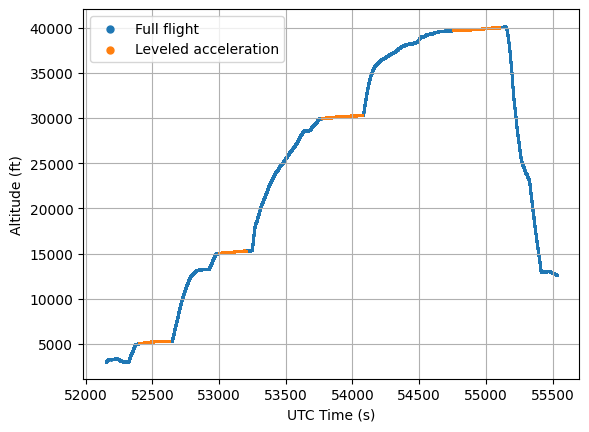

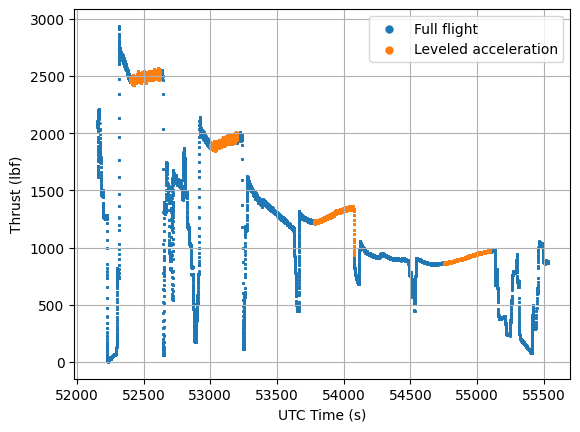

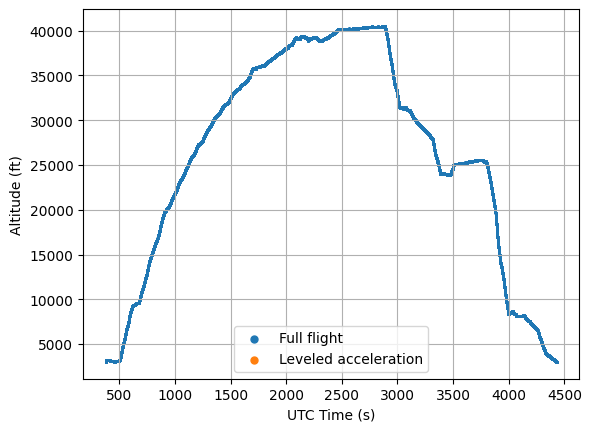

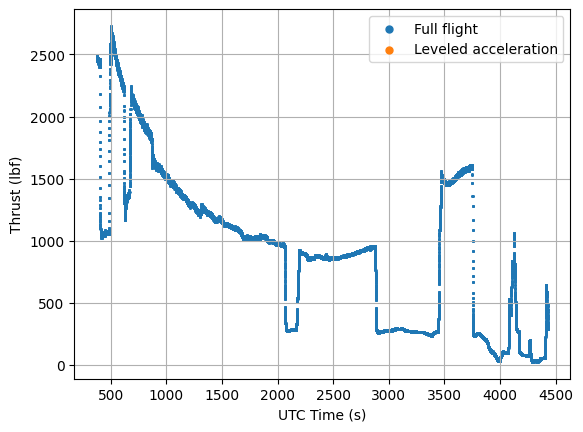

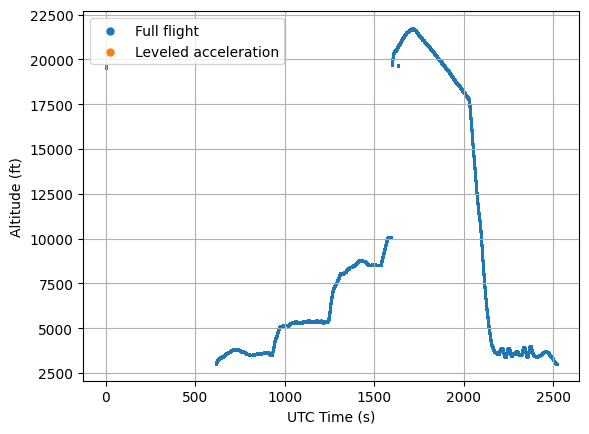

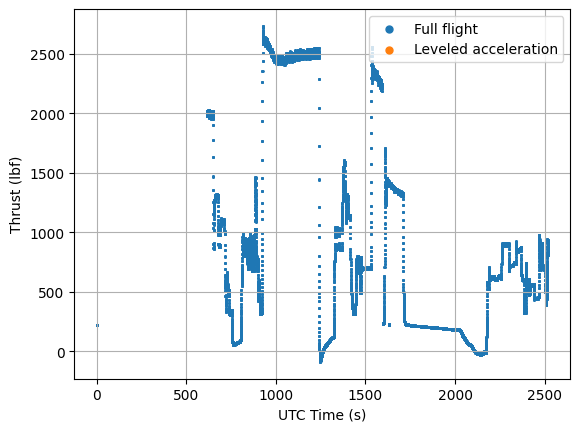

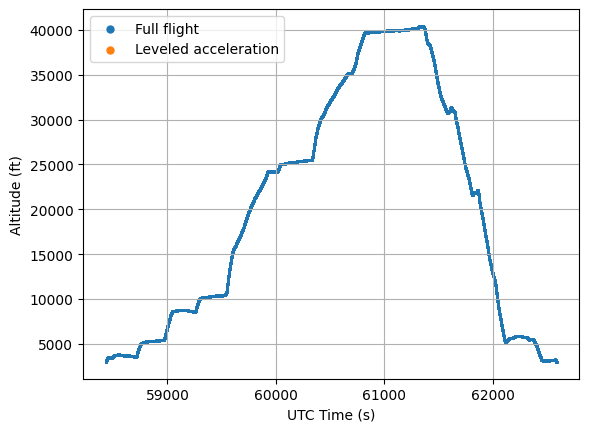

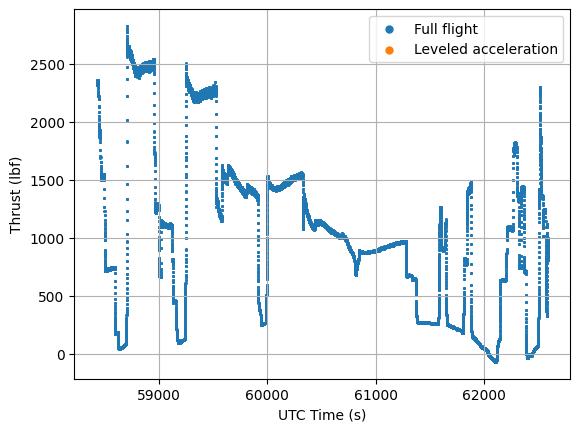

In [6]:
df = make_df('completo')
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

# subset = df[df['type'] == evaluated_set]

print(df['Alfa'].min())
print(df['Alfa'].max())

for filename, grupo in df.groupby('filename'):
    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    mask_leveled_acceleration = (
        ((grupo['TEMPO_SAD'] > 52400) & (grupo['TEMPO_SAD'] < 52625)) +
        ((grupo['TEMPO_SAD'] > 53000) & (grupo['TEMPO_SAD'] < 53200)) +
        ((grupo['TEMPO_SAD'] > 53775) & (grupo['TEMPO_SAD'] < 54075)) +
        ((grupo['TEMPO_SAD'] > 54750) & (grupo['TEMPO_SAD'] < 55100))
    )
    grupo_aceleracao_nivelada = grupo[mask_leveled_acceleration]
    grupo = grupo[mask]


    # plt.title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Zp'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['Zp'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Altitude (ft)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

    plt.scatter(grupo['TEMPO_SAD'], grupo['T'],      s=dot_size, label='Full flight')
    plt.scatter(grupo_aceleracao_nivelada['TEMPO_SAD'], grupo_aceleracao_nivelada['T'],      s=dot_size, label=f'Leveled acceleration')
    plt.xlabel('UTC Time (s)')
    plt.ylabel('Thrust (lbf)')
    plt.legend(markerscale=5)
    plt.grid()
    plt.show()

In [7]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['faixa_altitude'] == 'B', 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [8]:
def scale_data(df, features1, features2, targets):
    scaler_x1 = MinMaxScaler()
    scaler_x2 = MinMaxScaler()
    scaler_y  = MinMaxScaler()

    cols1 = features1
    cols2 = features2
    colsy = targets

    df[[p+'_scaled' for p in cols1]] = None
    df[[p+'_scaled' for p in cols2]] = None
    df[[p+'_scaled' for p in colsy]] = None

    # for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
    #     mask = df['type'] == split
    #     df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
    #     df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
    #     # df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])
    #     df.loc[mask, [p+'_scaled' for p in colsy]] = df.loc[mask, colsy].values  # sem escalonamento
    for split, method in [('train','fit_transform'), ('test','transform'), ('val','transform')]:
        mask = df['type'] == split
        df.loc[mask, [p+'_scaled' for p in cols1]] = getattr(scaler_x1, method)(df.loc[mask, cols1])
        df.loc[mask, [p+'_scaled' for p in cols2]] = getattr(scaler_x2, method)(df.loc[mask, cols2])
        df.loc[mask, [p+'_scaled' for p in colsy]] = getattr(scaler_y,  method)(df.loc[mask, colsy])

    return df, scaler_x1, scaler_x2, scaler_y

In [9]:
import tensorflow as tf

class PMGModel(keras.Model):
    def __init__(self, main_model, z1_model, ng_index, lambda_mono=1.0, **kwargs):
        super().__init__(**kwargs)
        self.main_model = main_model
        self.z1_model = z1_model
        self.ng_index = ng_index
        self.lambda_mono = lambda_mono
        self.penalty_tracker = keras.metrics.Mean(name='mono_penalty')
        self.total_loss_tracker = keras.metrics.Mean(name='total_loss')

    def call(self, inputs, training=False):
        return self.main_model(inputs, training=training)

    @property
    def metrics(self):
        return super().metrics + [self.penalty_tracker, self.total_loss_tracker]

    def _mono_penalty(self, x1, training):
        if self.ng_index is None or self.lambda_mono == 0:
            return tf.constant(0.0)
        with tf.GradientTape() as tape_phys:
            tape_phys.watch(x1)
            z1 = self.z1_model(x1, training=training)
        dz1_dx1 = tape_phys.gradient(z1, x1)
        dz1_dng = dz1_dx1[:, self.ng_index]
        return tf.reduce_mean(tf.nn.relu(-dz1_dng))

    def train_step(self, data):
        x, y = data
        x1, x2 = x
        with tf.GradientTape() as tape:
            penalty = self._mono_penalty(x1, training=True)
            y_pred = self.main_model([x1, x2], training=True)
            data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
            total_loss = data_loss + self.lambda_mono * penalty

        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

        self.penalty_tracker.update_state(penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)          # NOVO: faltava isso
            elif metric.name not in ('mono_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, data):
        x, y = data
        x1, x2 = x
        y_pred = self.main_model([x1, x2], training=False)
        data_loss = self.compute_loss(x=x, y=y, y_pred=y_pred)
        penalty = self._mono_penalty(x1, training=False)
        total_loss = data_loss + self.lambda_mono * penalty

        self.penalty_tracker.update_state(penalty)
        self.total_loss_tracker.update_state(total_loss)
        for metric in self.metrics:
            if metric.name == 'loss':
                metric.update_state(data_loss)          # NOVO: faltava isso
            elif metric.name not in ('mono_penalty', 'total_loss'):
                metric.update_state(y, y_pred)
        return {m.name: m.result() for m in self.metrics}

In [49]:
def build_model(features1, features2, architecture={}, hyperparameters={}):
    """
    Constrói duas sub-redes paralelas cujas saídas Z1 e Z2
    são combinadas por subtração (Z1 - Z2) para produzir Y.

    Args:
        features1 (list): Features da entrada X1.
        features2 (list): Features da entrada X2.
        architecture (dict):
            - neurons       (int):   Neurônios por camada oculta.
            - camadas_ocultas (int): Número de camadas ocultas em cada sub-rede.
            - activation    (str):   Função de ativação (ex: 'relu').
            - dropout       (float): Taxa de dropout após cada camada oculta (0 = sem dropout).
        hyperparameters (dict):
            - optimizer     (str):   Nome do otimizador (ex: 'adam').
            - learning_rate (float): Taxa de aprendizado.
            - epochs        (int):   Épocas de treino (armazenado como atributo do modelo).
            - batch_size    (int):   Batch size (armazenado como atributo do modelo).
            - patience      (int):   Paciência para EarlyStopping (armazenado como atributo).
    """
    neurons          = architecture.get('neurons', 32)
    n_hidden         = architecture.get('camadas_ocultas', 2)
    activation       = architecture.get('activation', 'relu')
    dropout_rate     = architecture.get('dropout', 0.0)

    optimizer_name   = hyperparameters.get('optimizer', 'adam')
    learning_rate    = hyperparameters.get('learning_rate', 0.001)
    epochs           = hyperparameters.get('epochs', 100)
    batch_size       = hyperparameters.get('batch_size', 32)
    patience         = hyperparameters.get('patience', 3)

    def build_subnetwork(input_tensor, name_prefix):
        """Empilha n camadas ocultas Dense + Dropout opcional."""
        x = input_tensor
        for i in range(n_hidden):
            x = layers.Dense(
                neurons,
                activation=activation,
                name=f'{name_prefix}_hidden_{i+1}'
            )(x)
            if dropout_rate > 0:
                x = layers.Dropout(dropout_rate, name=f'{name_prefix}_dropout_{i+1}')(x)
        z = layers.Dense(1, activation='softplus', name=f'{name_prefix}_output')(x)
        return z

    # --- Entradas ---
    input_x1 = layers.Input(shape=(len(features1),), name='Entrada_X1')
    input_x2 = layers.Input(shape=(len(features2),), name='Entrada_X2')

    # --- Sub-redes ---
    z1 = build_subnetwork(input_x1, name_prefix='NN1')
    z2 = build_subnetwork(input_x2, name_prefix='NN2')

    # --- Combinação e saída ---
    output = layers.Subtract(name='Saida_Y')([z1, z2])

    # --- Modelo funcional (igual a antes: usado para salvar/avaliar/extrair Z1,Z2) ---
    functional_model = Model(inputs=[input_x1, input_x2], outputs=output)

    # --- Sub-modelo que expõe só Z1, compartilhando as mesmas camadas de NN1 ---
    z1_model = Model(inputs=input_x1, outputs=z1, name='Z1_extractor')

    # --- Restrição física suave (estilo PINN): penaliza d(Z1)/d(NG) < 0 no treino ---
    mono_feature = hyperparameters.get('mono_feature', 'TEMPO_SAD')
    ng_index     = features1.index(mono_feature) if mono_feature in features1 else None
    lambda_mono  = hyperparameters.get('lambda_mono', 1.0)

    model = PMGModel(
        main_model=functional_model,
        z1_model=z1_model,
        ng_index=ng_index,
        lambda_mono=lambda_mono,
    )

    # --- Otimizador com learning rate customizado ---
    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })

    model.compile(optimizer=optimizer, loss='mse')

    # Armazena hiperparâmetros de treino como atributos para uso externo
    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model

In [11]:
def train_model(df, features1, features2, targets, model, hyperparameters):

    features1_scaled = []
    for item in features1:
        features1_scaled.append(item + '_scaled')

    features2_scaled = []
    for item in features2:
        features2_scaled.append(item + '_scaled')

    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    X1_train, X1_val = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features1_scaled]).astype(np.float32)
    X2_train, X2_val = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features2_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo...")
    training_history = model.fit(
        [X1_train, X2_train], Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=([X1_val, X2_val], Y_val),
        verbose=1
    )
    
    # O objeto `History` guarda uma referência ao próprio modelo em `.model`, que no
    # Keras 3 é uma property somente leitura (sem setter) — não dá pra fazer
    # `training_history.model = None` como antes. Como só usamos as curvas de loss
    # (`training_history.history`) daqui pra frente, serializamos apenas o dict,
    # evitando o hook de pickling do scikeras em cima do PMGModel.
    joblib.dump(training_history.history, './trainHistoryDict.pkl')

    # Para salvar/avaliar (e para o `extractor` que usa get_layer mais à frente),
    # usamos o modelo funcional puro — mesmos pesos, já atualizados pelo treino —
    # em vez do wrapper PMGModel, que só é necessário durante o fit().
    trained_model = model.main_model if isinstance(model, PMGModel) else model
    trained_model.save('./model.keras')

    return trained_model, training_history

In [12]:
def pipeline(tipo_dados, architecture, hyperparameters, features1, features2, targets, mode):
    df = make_df(tipo_dados)
    df = split_train_test_val(df)
    df, scaler_x1, scaler_x2, scaler_y = scale_data(df, features1, features2, targets)

    if mode == 'train':
        model = build_model(features1, features2, architecture, hyperparameters)
        model, training_history = train_model(df, features1, features2, targets, model, hyperparameters)
    elif mode == 'read':
        print('Carregando o modelo...')
        model, training_history = keras.models.load_model('./model.keras'), joblib.load('./trainHistoryDict.pkl')
    return df, scaler_x1, scaler_x2, scaler_y, model, training_history

In [28]:
def evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set='test'):

    features1_scaled = [item + '_scaled' for item in features1]
    features2_scaled = [item + '_scaled' for item in features2]

    # Previsão sobre todo o dataframe
    X_all = [
        np.array(df[features1_scaled]).astype(np.float32),
        np.array(df[features2_scaled]).astype(np.float32)
    ]

    pred_scaled_all = model.predict(X_all)
    pred_all = scaler_y.inverse_transform(pred_scaled_all)
    # pred_all = pred_scaled_all

    for i, item in enumerate(targets):
        df[item + '_pred'] = pred_all[:, i]

    # Monta results somente com o subconjunto avaliado
    mask = df['type'] == evaluated_set

    pred = pred_all[mask.values]
    real = np.array(df.loc[mask, targets]).astype(np.float32)

    erro = abs(pred - real)
    avg_error = np.nanmean(erro, axis=0).astype(np.float32)


    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }

    return results, df

In [30]:
def analyze (
        tipo_dados,
        features1,
        features2,
        targets,
        architecture={
            'neurons': 32,
            'camadas_ocultas': 3,
            'activation': 'relu',
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': 'adam',
            'learning_rate': 0.0001,
            'epochs': 200,
            'batch_size': 64,
            'patience': 4,
            'lambda_mono': 1.0,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
        },
        # architecture={
        #     'neurons': 5,
        #     'camadas_ocultas': 1,
        #     'activation': 'relu',
        #     'dropout': 0
        # },
        # hyperparameters={
        #     'optimizer': 'adam',
        #     'learning_rate': 0.01,
        #     'epochs': 2,
        #     'batch_size': 64,
        #     'patience': 2
        # },
        evaluated_set='test',
        mode='train'
        ):
    df, scaler_x1, scaler_x2, scaler_y, model, training_history = pipeline(
        tipo_dados=tipo_dados,
        architecture=architecture,
        hyperparameters=hyperparameters,
        features1=features1,
        features2=features2,
        targets=targets,
        mode=mode
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results, df = evaluate(model, df, features1, features2, targets, scaler_y, evaluated_set)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        # figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Comparação de {item} Real vs. Predito')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}'], dot_size, label=f'{item} Real')
        axs[2*i].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], df.loc[df['type']==evaluated_set][f'{item}_pred'], dot_size, label=f'{item} Predito')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Erro médio (|pre-real|): {results["avg_error"][i]:.2f}')
        axs[2*i+1].scatter(df.loc[df['type'] == evaluated_set]['TEMPO_SAD'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()

    plt.savefig(f'figures/{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x1, scaler_x2, scaler_y, model, training_history, results

Treinando modelo com 1 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 482us/step


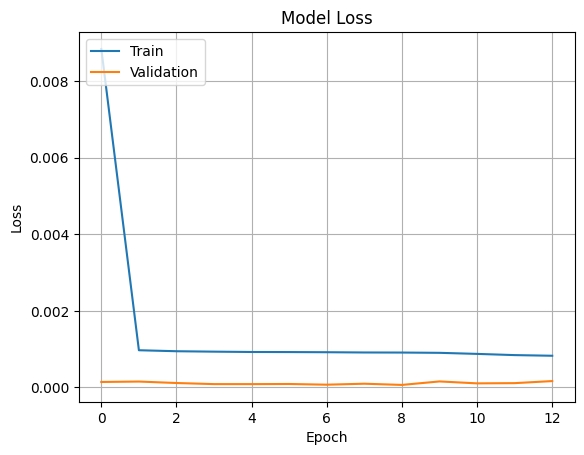

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


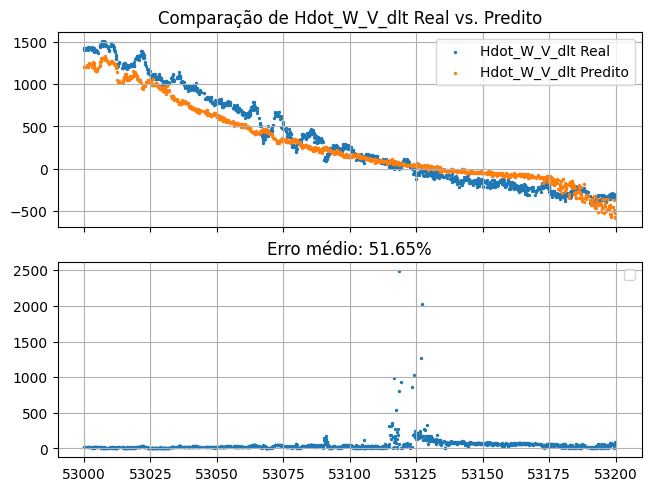

Treinando modelo com 1 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 483us/step


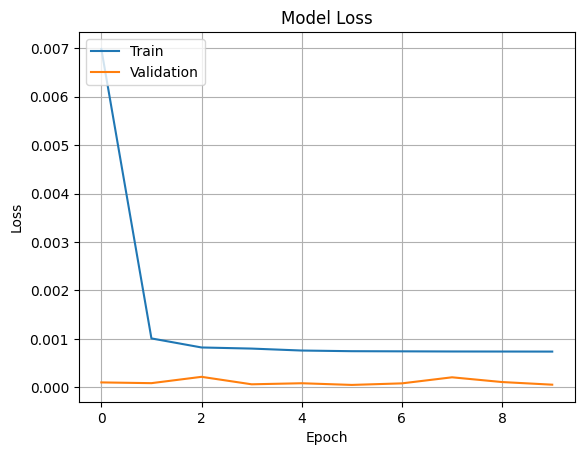

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


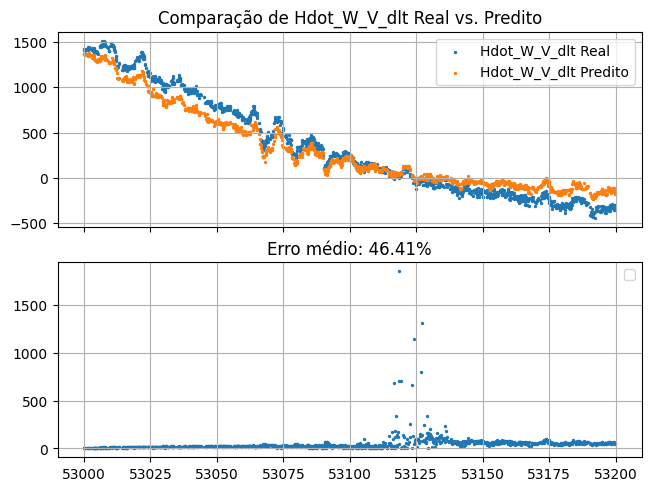

Treinando modelo com 1 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 500us/step


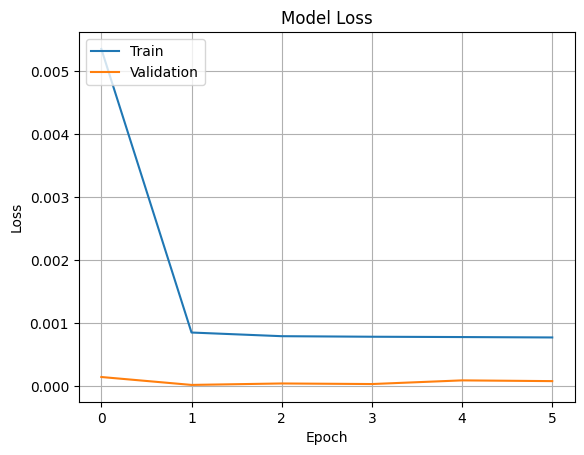

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


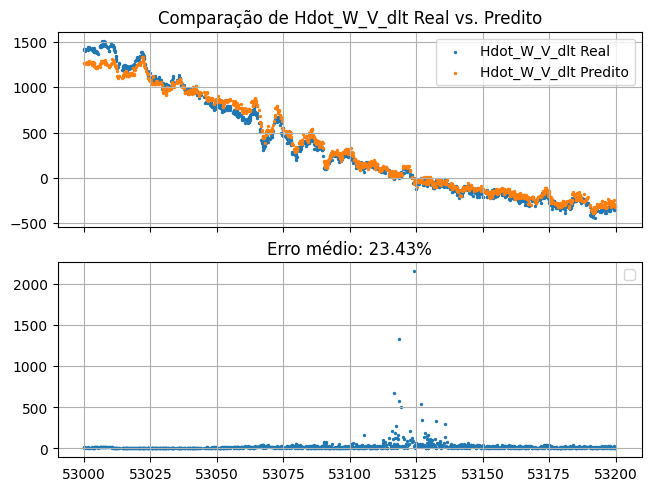

Treinando modelo com 1 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 485us/step


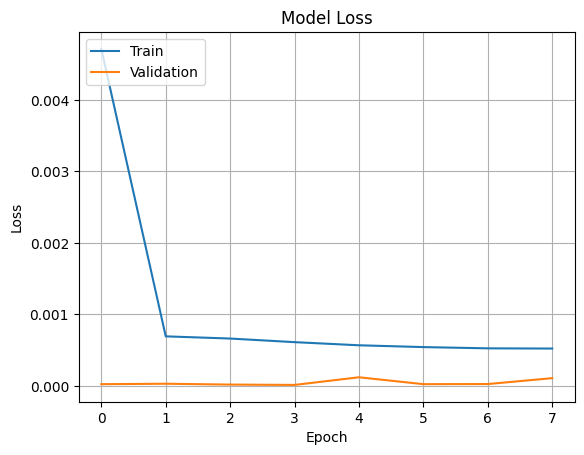

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


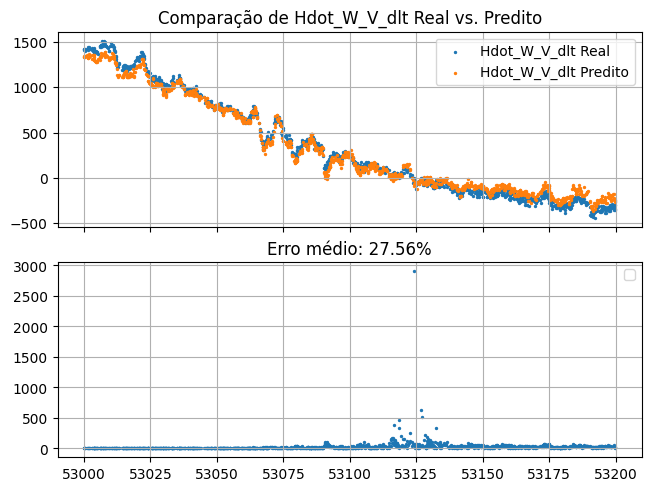

Treinando modelo com 2 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 533us/step


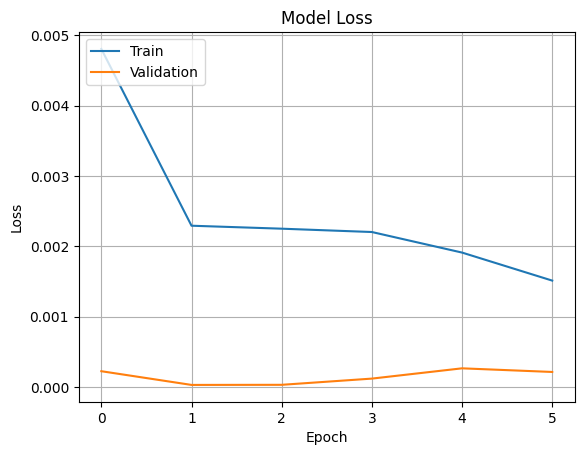

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


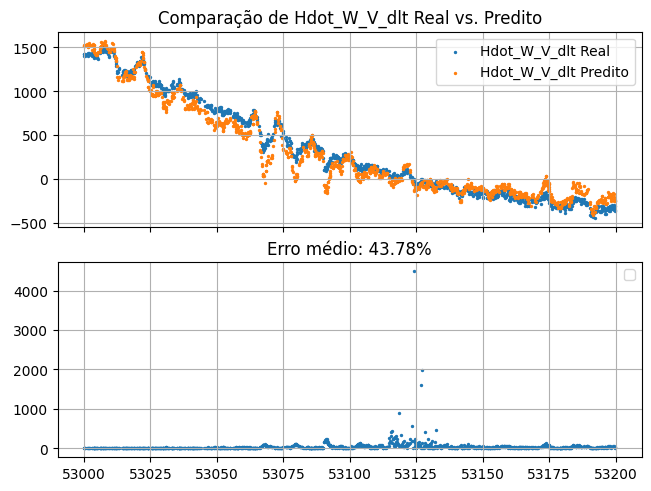

Treinando modelo com 2 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 547us/step


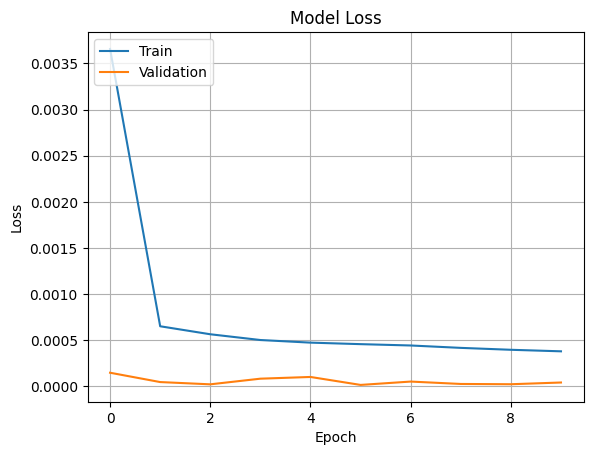

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


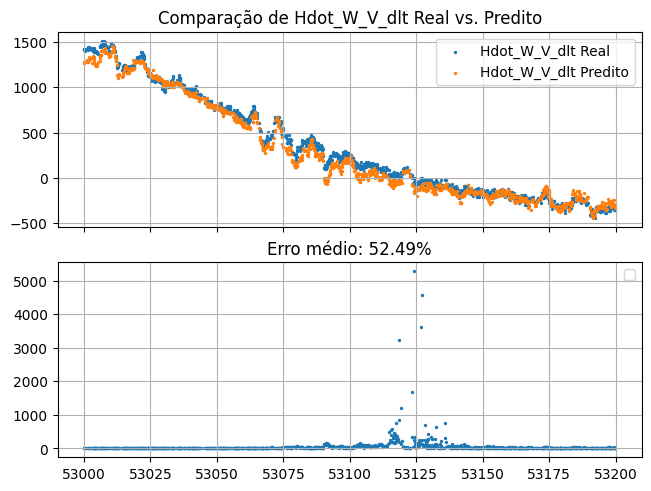

Treinando modelo com 2 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 527us/step


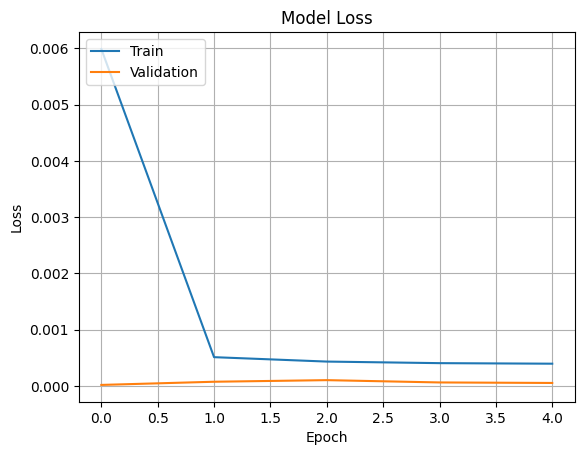

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


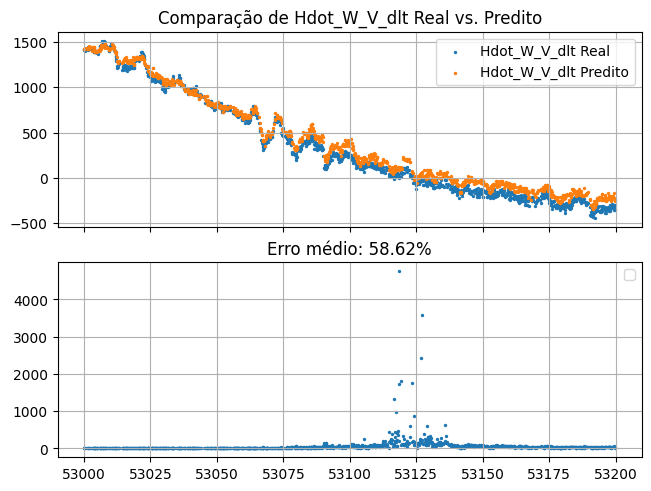

Treinando modelo com 2 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 535us/step


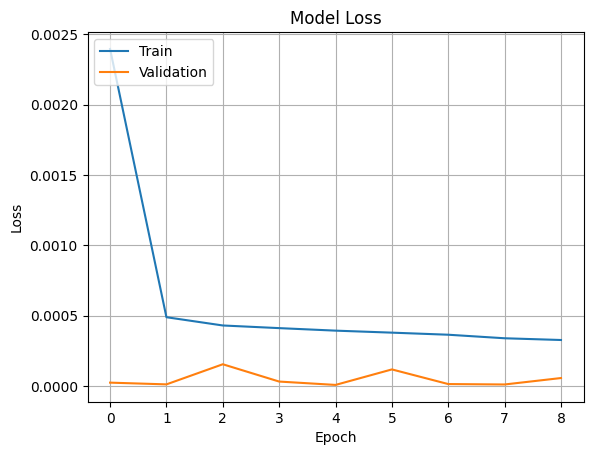

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


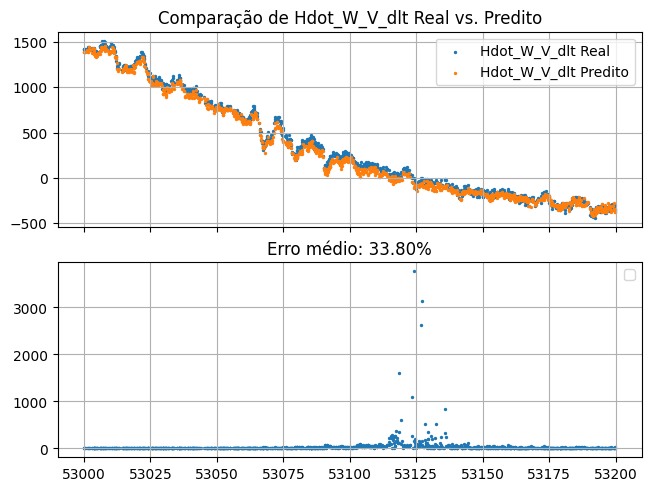

Treinando modelo com 3 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 638us/step


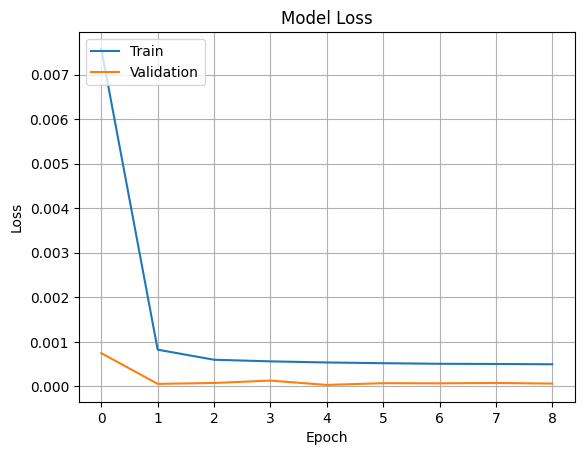

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


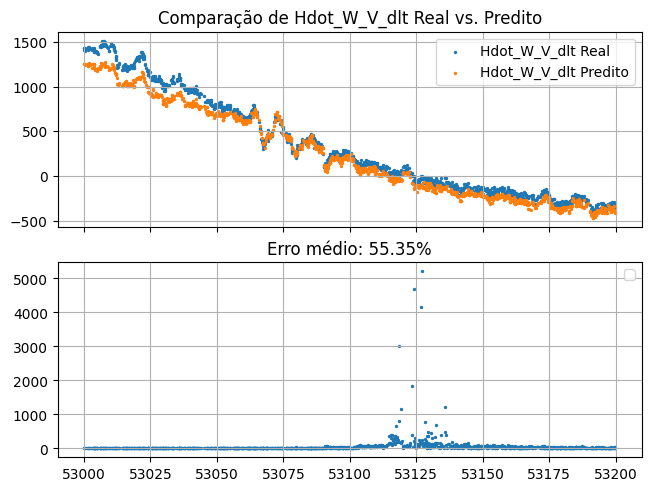

Treinando modelo com 3 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 504us/step


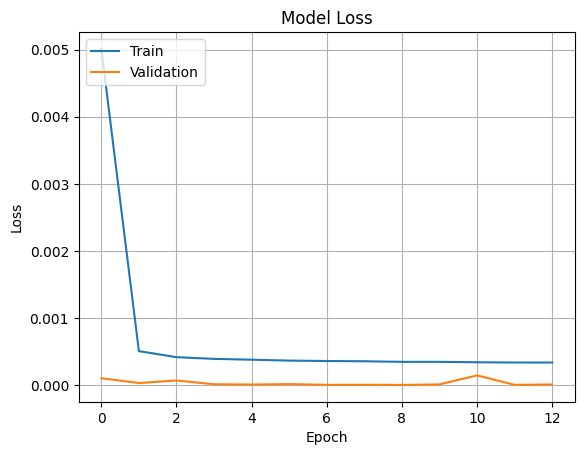

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


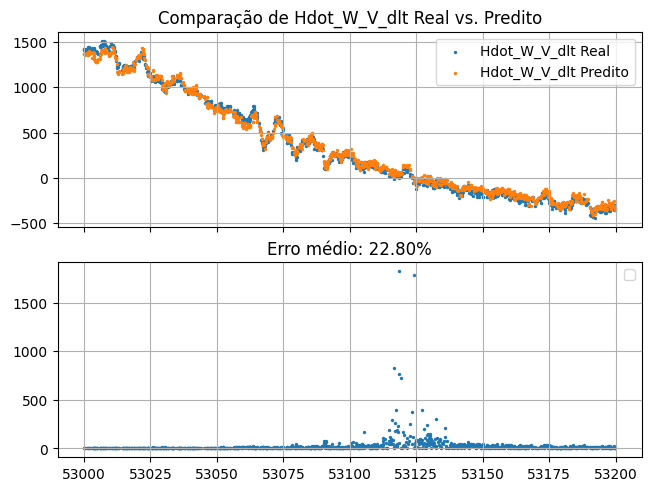

Treinando modelo com 3 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 525us/step


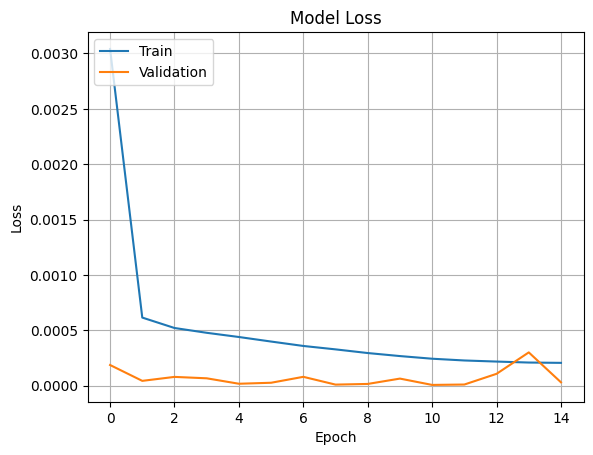

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


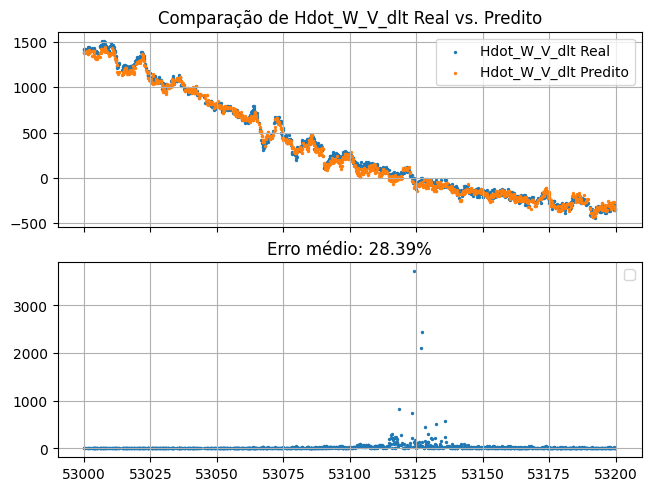

Treinando modelo com 3 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 543us/step


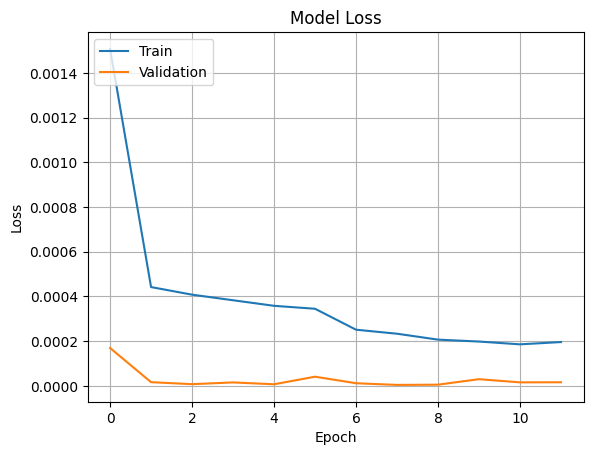

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


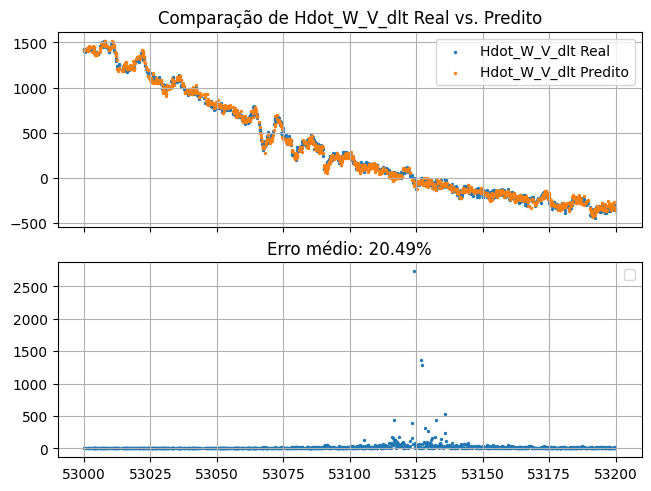

Treinando modelo com 4 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 566us/step


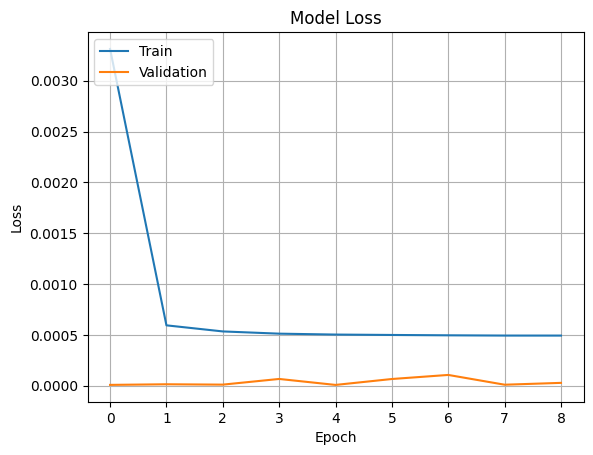

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


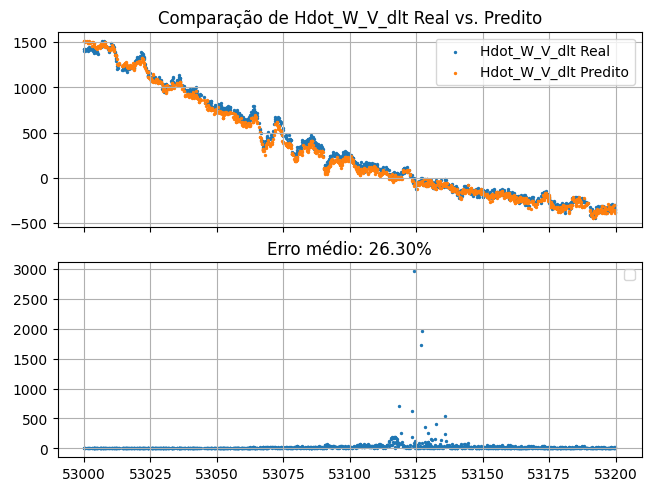

Treinando modelo com 4 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 515us/step


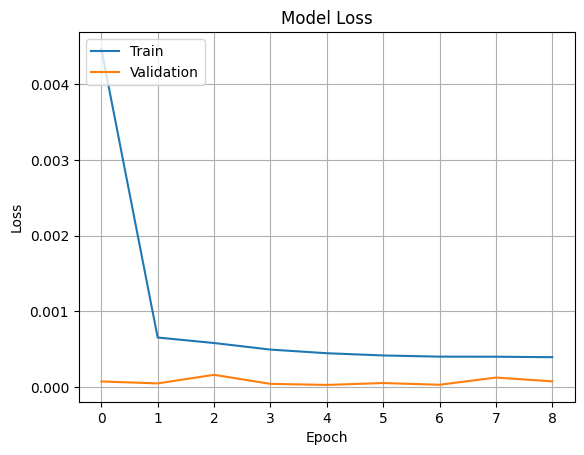

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


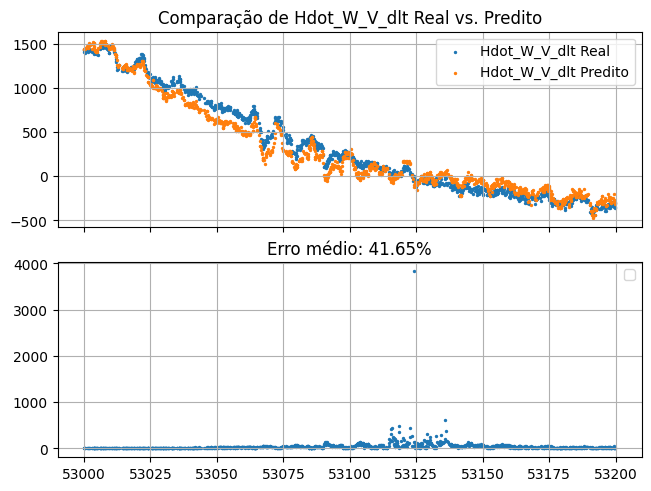

Treinando modelo com 4 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 559us/step


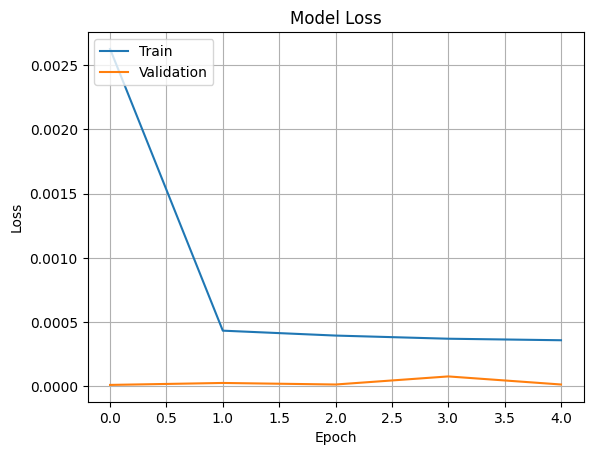

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


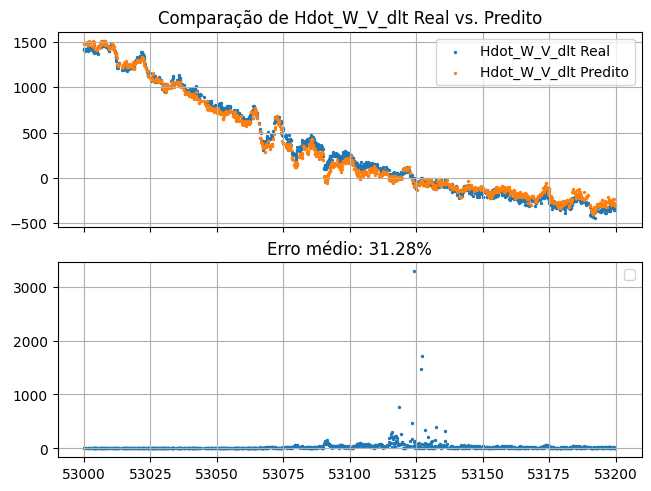

Treinando modelo com 4 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 558us/step


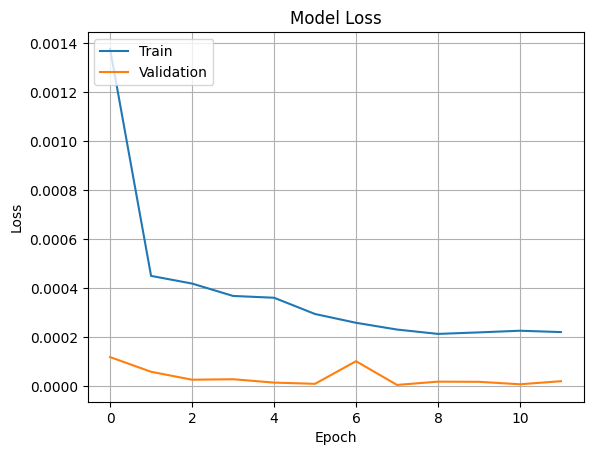

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


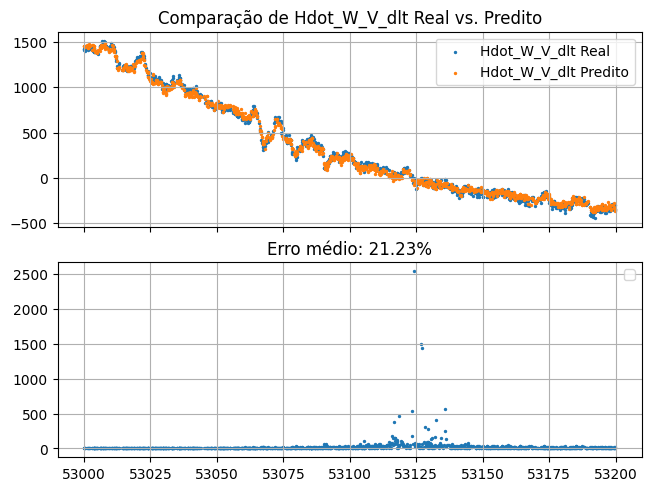

Treinando modelo com 5 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 583us/step


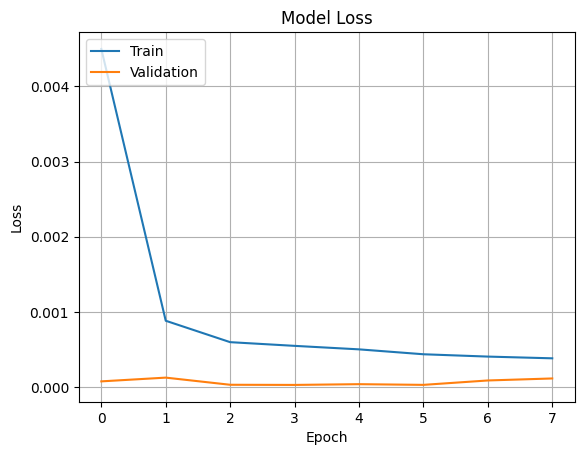

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


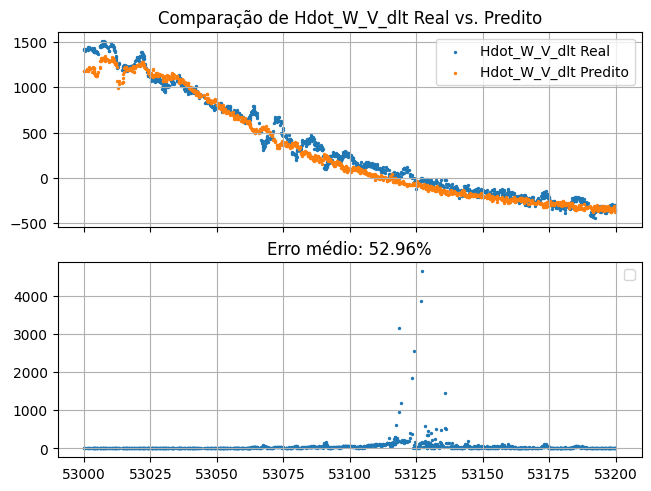

Treinando modelo com 5 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 557us/step


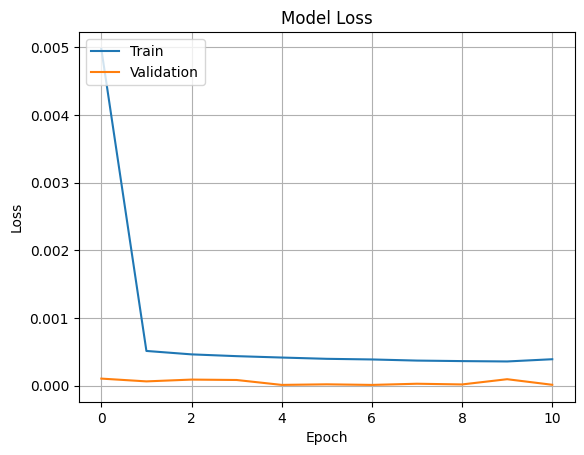

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


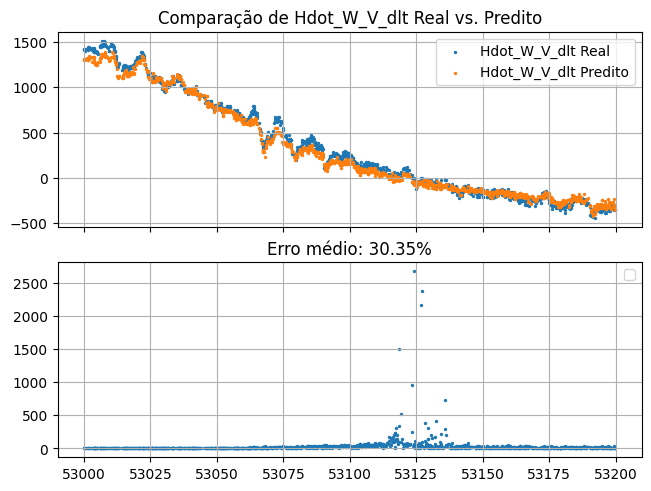

Treinando modelo com 5 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 565us/step


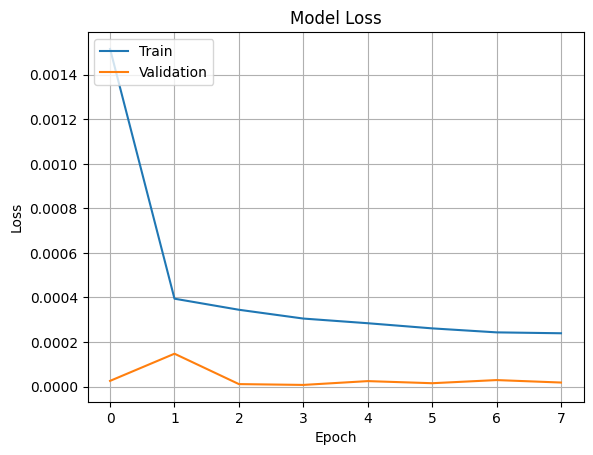

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


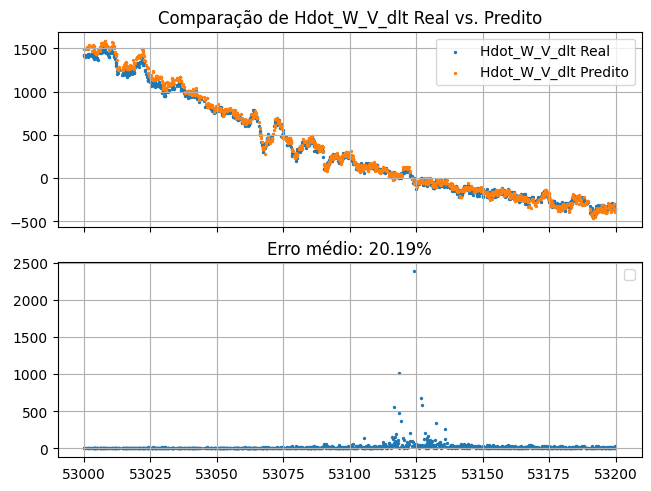

Treinando modelo com 5 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 561us/step


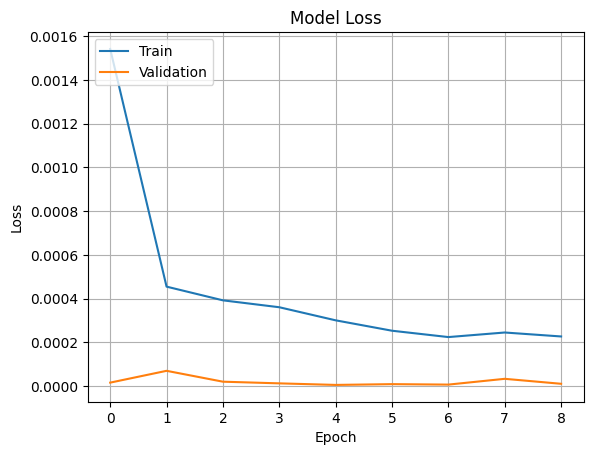

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


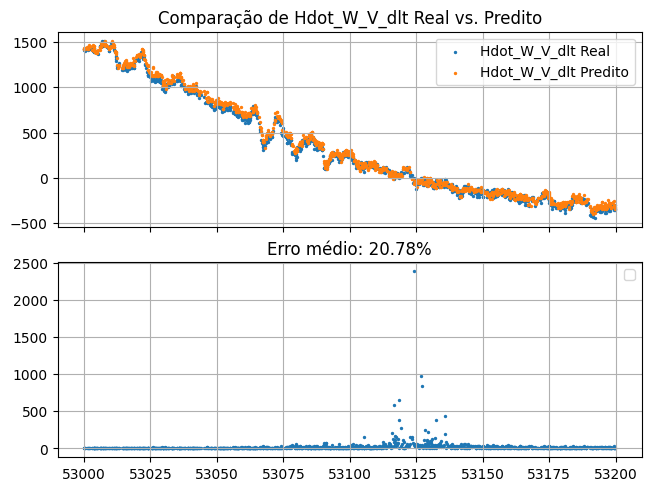

Treinando modelo com 6 camadas, 5 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 556us/step


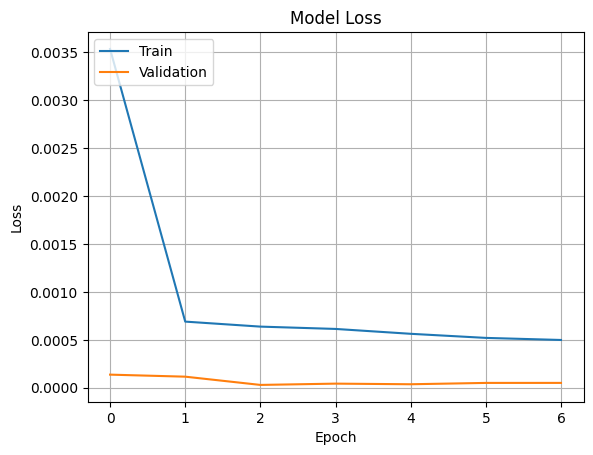

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


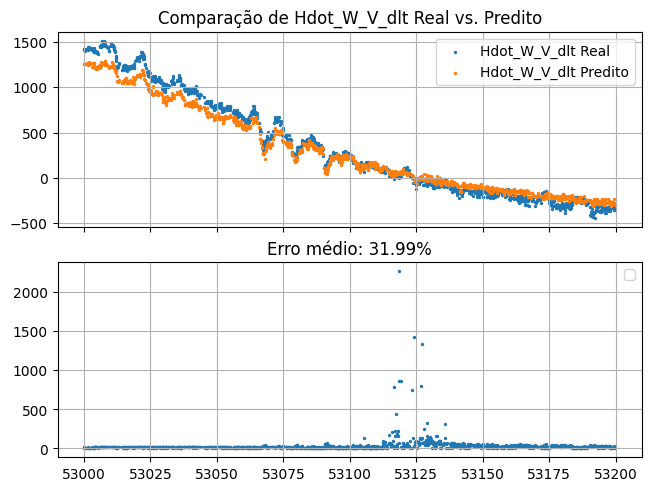

Treinando modelo com 6 camadas, 10 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 586us/step


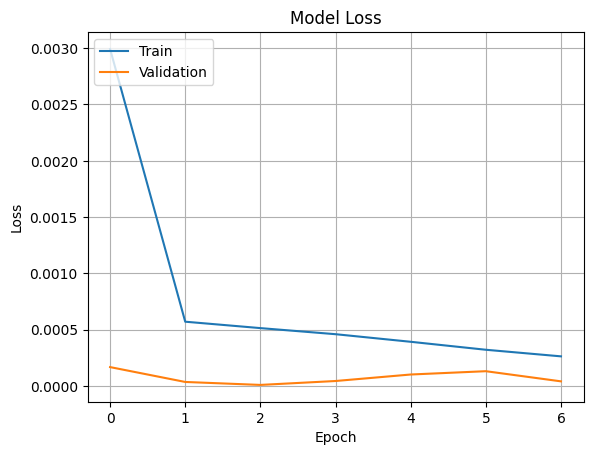

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


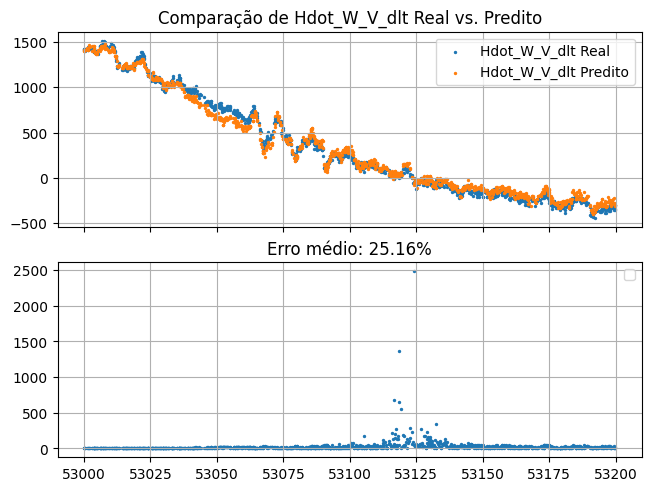

Treinando modelo com 6 camadas, 20 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 550us/step


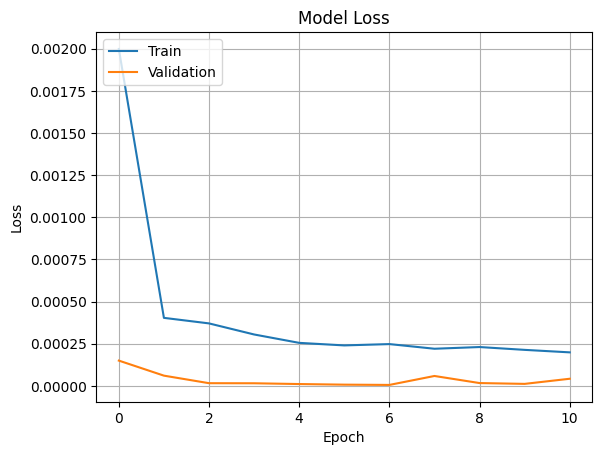

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


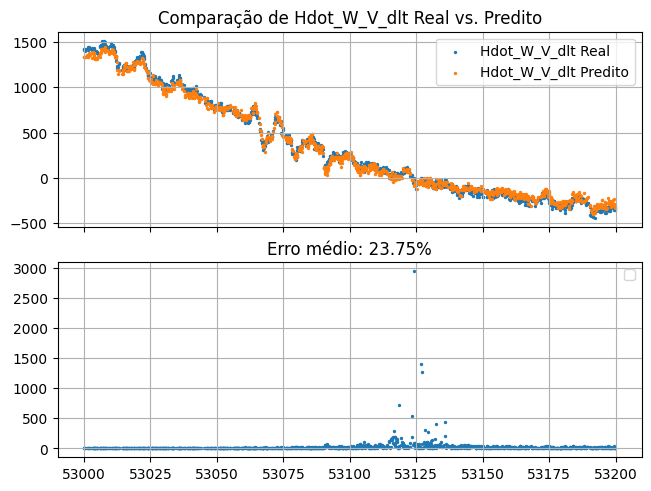

Treinando modelo com 6 camadas, 50 neurônios e lambda_mono = 0...
Treinando modelo...
3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 606us/step


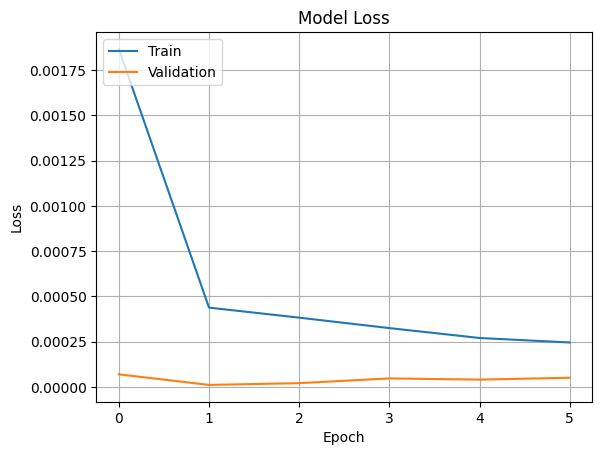

C:\Users\ymarc\AppData\Local\Temp\ipykernel_16848\1746279968.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


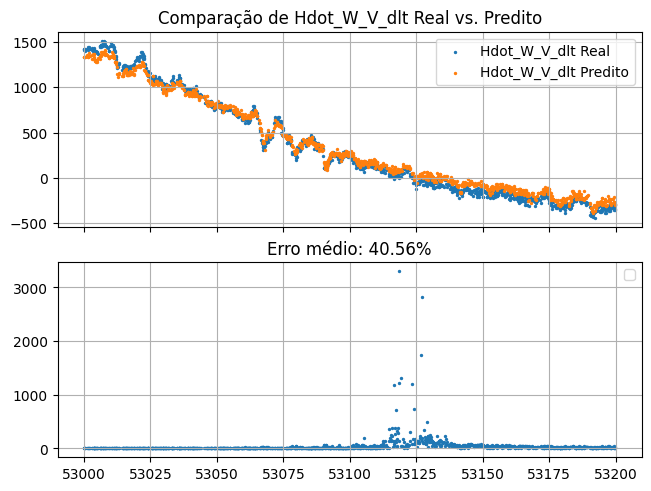

In [18]:
camadas = [1, 2, 3, 4, 5, 6]
neuronios = [5, 10, 20, 50]
# lambda_mono_values = [0, 0.01,  0.1, 0.5, 1.0, 100.0]
lambda_mono_values = [0]
# camadas = [3]
# neuronios = [20]
# lambda_mono_values = [0.1]
lista_resultados = []
for camada in camadas:
    for neuronio in neuronios:
        for lambda_mono in lambda_mono_values:
            print(f"Treinando modelo com {camada} camadas, {neuronio} neurônios e lambda_mono = {lambda_mono}...")
            resultados = analyze(
                tipo_dados='completo',
            features1=['Mach', 'N1_over_sqrt_theta'],
            features2=['Mach', 'NZ_W_dlt'],
            targets=['Hdot_W_V_dlt'],
            mode='train',
            architecture={
                'neurons': neuronio,
                'camadas_ocultas': camada,
                'activation': 'relu',
                'dropout': 0
            },
            hyperparameters={
                'optimizer': 'adam',
                'learning_rate': 0.001,
                'epochs': 100,
                'batch_size': 32,
                'patience': 4,
                'lambda_mono': lambda_mono,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
            })
            lista_resultados.append(resultados)
    

In [19]:
# =========================================================
# Relatório em PDF do grid search (camadas x neurônios x lambda_mono)
# Lê os resultados salvos em `lista_resultados` (mesma ordem de geração:
# for camada -> for neuronio -> for lambda_mono) e monta um PDF com:
#   - tabela resumo (camadas, neurônios, lambda_mono, erro médio no teste, épocas)
#   - 1 página por combinação, reproduzindo os DOIS gráficos que analyze() já plota:
#     (1) loss de treino/validação e (2) real vs. predito + erro relativo
# =========================================================
import itertools
import os
import matplotlib.pyplot as plt
from reportlab.lib.pagesizes import A4
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image, PageBreak, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

TARGET = 'Hdot_W_V_dlt'   # ajuste aqui se o target do loop de treino mudar
EVALUATED_SET = 'test'

combinacoes = list(itertools.product(camadas, neuronios, lambda_mono_values))

assert len(combinacoes) == len(lista_resultados), (
    f"Número de combinações esperadas ({len(combinacoes)}) difere do número de "
    f"resultados em lista_resultados ({len(lista_resultados)}). Rode novamente a célula "
    "de treino (com o append corrigido) antes de gerar o relatório."
)

OUT_DIR = 'figures/grid_search_report'
os.makedirs(OUT_DIR, exist_ok=True)

styles = getSampleStyleSheet()
title_style = styles['Heading2']
body_style = styles['Normal']

doc = SimpleDocTemplate(
    'relatorio_grid_search.pdf',
    pagesize=A4,
    topMargin=1.5 * cm, bottomMargin=1.5 * cm, leftMargin=2 * cm, rightMargin=2 * cm
)
story = []

story.append(Paragraph('Grid Search — camadas x neurônios x lambda_mono', styles['Title']))
story.append(Spacer(1, 12))
story.append(Paragraph(
    f'{len(combinacoes)} combinações treinadas '
    f'({len(camadas)} camadas × {len(neuronios)} neurônios × {len(lambda_mono_values)} lambda_mono). '
    'A tabela abaixo resume cada caso; nas páginas seguintes, cada combinação tem sua própria página '
    'com a curva de loss de treino/validação e a comparação real vs. predito + erro relativo no conjunto de teste.',
    body_style
))
story.append(Spacer(1, 12))

resumo_data = [['#', 'Camadas', 'Neurônios', 'lambda_mono', 'Erro médio teste (%)', 'Épocas treinadas']]
for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    _, _, _, _, _, training_history, results = lista_resultados[idx]
    erro = results['avg_error'][0] if results is not None else float('nan')
    n_epochs = len(training_history.history['loss'])
    resumo_data.append([str(idx + 1), str(camada), str(neuronio), str(lambda_mono), f'{erro:.2f}', str(n_epochs)])

tabela = Table(resumo_data, repeatRows=1)
tabela.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#2c3e50')),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('FONTSIZE', (0, 0), (-1, -1), 8),
    ('GRID', (0, 0), (-1, -1), 0.25, colors.grey),
    ('ROWBACKGROUNDS', (0, 1), (-1, -1), [colors.white, colors.HexColor('#f2f2f2')]),
    ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
]))
story.append(tabela)
story.append(PageBreak())

for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    df, _, _, _, _, training_history, results = lista_resultados[idx]
    hist = training_history.history
    mask = df['type'] == EVALUATED_SET

    fig = plt.figure(figsize=(8, 10), constrained_layout=True)
    gs = fig.add_gridspec(3, 1, height_ratios=[1, 1.3, 1])

    ax_loss = fig.add_subplot(gs[0])
    ax_loss.plot(hist['loss'], label='Train')
    ax_loss.plot(hist['val_loss'], label='Validation')
    ax_loss.set_title('Model Loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend(loc='upper right')
    ax_loss.grid(True)

    ax_cmp = fig.add_subplot(gs[1])
    ax_cmp.scatter(df.loc[mask, 'TEMPO_SAD'], df.loc[mask, TARGET], s=2, label=f'{TARGET} Real')
    ax_cmp.scatter(df.loc[mask, 'TEMPO_SAD'], df.loc[mask, f'{TARGET}_pred'], s=2, label=f'{TARGET} Predito')
    ax_cmp.set_title(f'Comparação de {TARGET} Real vs. Predito')
    ax_cmp.legend()
    ax_cmp.grid(True)

    ax_err = fig.add_subplot(gs[2])
    ax_err.scatter(df.loc[mask, 'TEMPO_SAD'], results['rel_error'][:, 0], s=2)
    ax_err.set_title(f'Erro médio: {results["avg_error"][0]:.2f}%')
    ax_err.grid(True)

    fig.suptitle(f'{camada} camada(s), {neuronio} neurônios, λ_mono = {lambda_mono}', fontsize=13)

    img_path = f'{OUT_DIR}/caso_{idx + 1:03d}.png'
    fig.savefig(img_path, dpi=150)
    plt.close(fig)

    story.append(Paragraph(
        f'Caso {idx + 1}/{len(combinacoes)} — Camadas: {camada} | Neurônios: {neuronio} | lambda_mono: {lambda_mono}',
        title_style
    ))
    story.append(Spacer(1, 6))
    story.append(Image(img_path, width=14 * cm, height=17.5 * cm))
    story.append(PageBreak())

doc.build(story)
print(f'Relatório salvo em relatorio_grid_search.pdf ({len(combinacoes)} casos, 1 página de gráficos por caso).')

Relatório salvo em relatorio_grid_search.pdf (24 casos, 1 página de gráficos por caso).


In [20]:
# =========================================================
# Salvar os resultados do grid search (versão leve e "picklable")
# NÃO fazemos pickle de `lista_resultados` diretamente: cada item carrega um
# modelo Keras inteiro, e isso já quebrou antes (History.model + hook do scikeras
# tentando serializar via get_config()). Em vez disso, extraímos só o que o
# relatório precisa: hiperparâmetros, histórico de loss (dict simples) e os
# resultados de teste (arrays numpy + um recorte pequeno do df).
# =========================================================
import itertools
import os
import pickle

TARGET = 'Hdot_W_V_dlt'   # mesmo target usado no loop de treino
EVALUATED_SET = 'test'

os.makedirs('resultados_grid_search', exist_ok=True)

combinacoes = list(itertools.product(camadas, neuronios, lambda_mono_values))
assert len(combinacoes) == len(lista_resultados), (
    f"Número de combinações esperadas ({len(combinacoes)}) difere do número de "
    f"resultados em lista_resultados ({len(lista_resultados)})."
)

resultados_leves = []
for idx, (camada, neuronio, lambda_mono) in enumerate(combinacoes):
    df, _, _, _, model, training_history, results = lista_resultados[idx]
    mask = df['type'] == EVALUATED_SET
    df_test = df.loc[mask, ['TEMPO_SAD', TARGET, f'{TARGET}_pred', 'type']].copy()

    resultados_leves.append({
        'camadas': camada,
        'neuronios': neuronio,
        'lambda_mono': lambda_mono,
        'history': training_history.history,   # dict simples (loss/val_loss), picklable
        'results': results,                    # dict com predicted/real/rel_error/avg_error
        'df_test': df_test,                    # só as colunas usadas no relatório
    })

    # Opcional: salvar o modelo treinado para reuso futuro.
    # Use o formato nativo do Keras, NÃO pickle do objeto `model`:
    # model.save(f'resultados_grid_search/modelo_{idx + 1:03d}.keras')

with open('resultados_grid_search/lista_resultados.pkl', 'wb') as f:
    pickle.dump(resultados_leves, f)

print(f"Salvos {len(resultados_leves)} resultados em resultados_grid_search/lista_resultados.pkl")

Salvos 24 resultados em resultados_grid_search/lista_resultados.pkl


In [21]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = lista_resultados[-1]  # último resultado do grid search

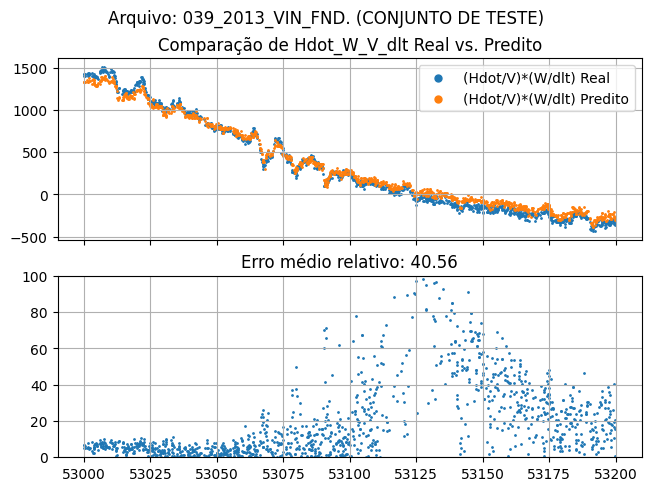

In [22]:
evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_mse = (grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt'])**2 / grupo['Hdot_W_V_dlt'].abs() * 100

    erro_relativo = abs((grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']) / grupo['Hdot_W_V_dlt'].abs() * 100)

    _, axs = plt.subplots(2, 1, sharex=True, constrained_layout=True)
    _.suptitle(f'Arquivo: {filename}. (CONJUNTO DE TESTE)')

    axs[0].set_title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'],      s=dot_size, label='(Hdot/V)*(W/dlt) Real')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='(Hdot/V)*(W/dlt) Predito')
    axs[0].legend(markerscale=5)
    axs[0].grid()

    axs[1].set_title(f'Erro médio relativo: {erro_relativo.mean():.2f}')
    axs[1].scatter(grupo['TEMPO_SAD'], erro_relativo, s=dot_size)
    axs[1].set_ylim(0, 100)
    axs[1].grid()

    # axs[2].set_title(f'Erro médio (MSE): {erro_mse.mean():.2f}')
    # axs[2].scatter(grupo['TEMPO_SAD'], erro_mse, s=dot_size)
    # # axs[1].set_ylim(-100, 100)
    # axs[2].grid()

    plt.show()

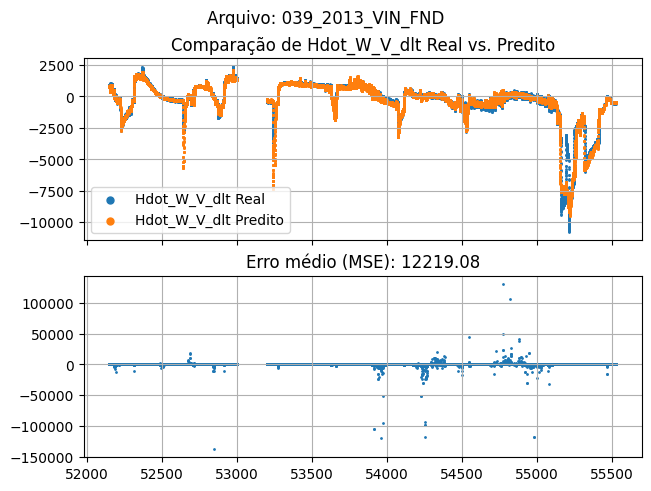

In [23]:
evaluated_set = 'train'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_medio_mse = np.nanmean(
        (grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt'])**2 / grupo['Hdot_W_V_dlt'].abs() * 100
    )
    erro_relativo = (grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']) / grupo['Hdot_W_V_dlt'].abs() * 100

    _, axs = plt.subplots(2, 1, sharex=True, constrained_layout=True)
    _.suptitle(f'Arquivo: {filename}')

    axs[0].set_title('Comparação de Hdot_W_V_dlt Real vs. Predito')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'],      s=dot_size, label='Hdot_W_V_dlt Real')
    axs[0].scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt Predito')
    axs[0].legend(markerscale=5)
    axs[0].grid()

    axs[1].set_title(f'Erro médio (MSE): {erro_medio_mse:.2f}')
    axs[1].scatter(grupo['TEMPO_SAD'], erro_relativo, s=dot_size)
    # axs[1].set_ylim(-100, 100)
    axs[1].grid()

    plt.show()

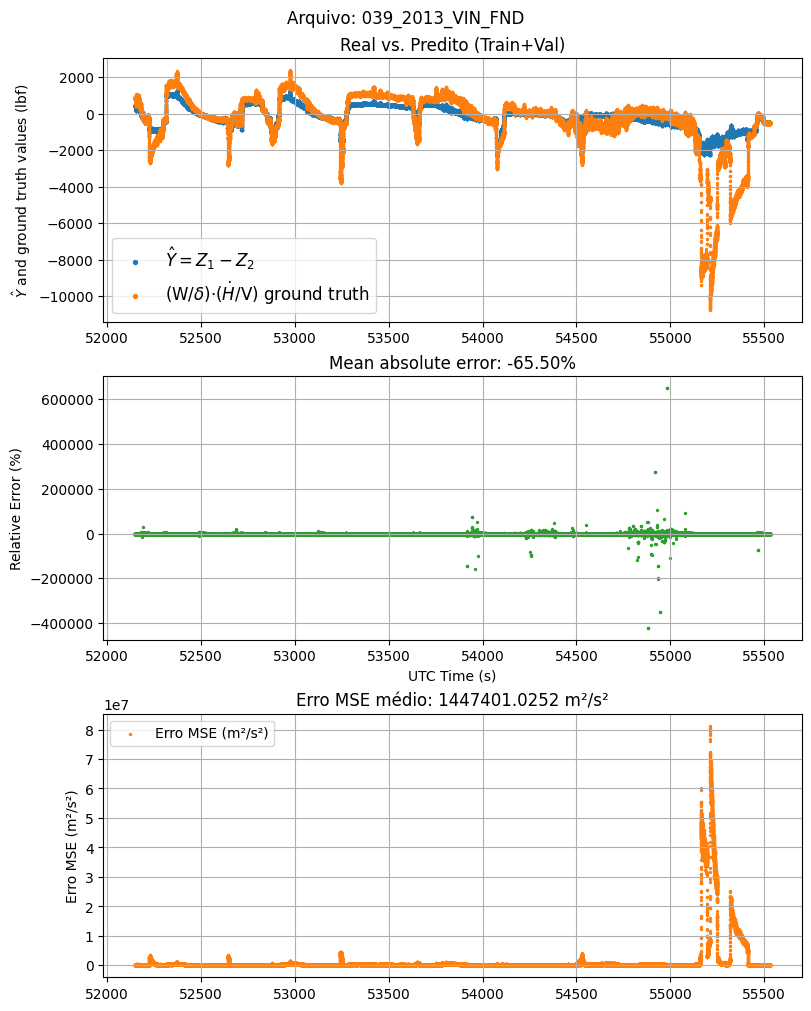

In [116]:
train_val = df[df['type'].isin(['train', 'val'])]
time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        # '041_2013_GEO_AIR': (5e5, 8e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

for filename, grupo in train_val.groupby('filename'):
    t0, t = time_intervals[filename]

    grupo['erro_mse'] = (grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']) ** 2
    grupo['erro_relativo'] = (grupo['Hdot_W_V_dlt_pred'] - grupo['Hdot_W_V_dlt']) / grupo['Hdot_W_V_dlt'] * 100

    fig, axes = plt.subplots(3, 1, figsize=(8, 10), constrained_layout=True)
    fig.suptitle(f'Arquivo: {filename}', fontsize=12)

    # Predito vs. Real
    axes[0].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'Hdot_W_V_dlt_pred'], label=r'$\hat{Y} = Z_1 - Z_2$', s=2)
    axes[0].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'Hdot_W_V_dlt'],      label=r'(W/$\delta$)$\cdot$($\dot{H}$/V) ground truth',    s=2)
    axes[0].set_ylabel(r'$\hat{Y}$ and ground truth values (lbf)')
    axes[0].set_title('Real vs. Predito (Train+Val)')
    axes[0].legend(markerscale=2, fontsize=12)
    axes[0].grid()

    # Erro Relativo
    axes[1].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_relativo'], label='Erro Relativo (%)', s=2, color='tab:green')
    axes[1].set_ylabel('Relative Error (%)')
    axes[1].set_xlabel('UTC Time (s)')
    axes[1].set_title('Mean absolute error: {:.2f}%'.format(np.nanmean(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_relativo'])))
    # axes[1].set_ylim(-100, 100)
    # axes[1].legend(markerscale=1)
    axes[1].grid()

    # Erro MSE
    axes[2].scatter(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'TEMPO_SAD'], grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_mse'], label='Erro MSE (m²/s²)', s=2, color='tab:orange')
    axes[2].set_ylabel('Erro MSE (m²/s²)')
    axes[2].set_title('Erro MSE médio: {:.4f} m²/s²'.format(np.nanmean(grupo.loc[grupo['TEMPO_SAD'].between(t0, t), 'erro_mse'])))
    axes[2].legend(markerscale=1)
    axes[2].grid()

    plt.show()

Treinando modelo...
Epoch 1/100
3177/3177 ━━━━━━━━━━━━━━━━━━━━ 4s 941us/step - loss: 0.0073 - mono_penalty: 0.0000e+00 - total_loss: 0.0073 - val_loss: 4.5034e-05 - val_mono_penalty: 0.0000e+00 - val_total_loss: 4.5034e-05
Epoch 2/100
3177/3177 ━━━━━━━━━━━━━━━━━━━━ 3s 908us/step - loss: 5.9835e-04 - mono_penalty: 0.0000e+00 - total_loss: 5.9835e-04 - val_loss: 3.3375e-05 - val_mono_penalty: 0.0000e+00 - val_total_loss: 3.3375e-05
Epoch 3/100
3177/3177 ━━━━━━━━━━━━━━━━━━━━ 3s 902us/step - loss: 4.9311e-04 - mono_penalty: 0.0000e+00 - total_loss: 4.9311e-04 - val_loss: 3.0705e-05 - val_mono_penalty: 0.0000e+00 - val_total_loss: 3.0705e-05
Epoch 4/100
3177/3177 ━━━━━━━━━━━━━━━━━━━━ 3s 893us/step - loss: 4.4295e-04 - mono_penalty: 0.0000e+00 - total_loss: 4.4295e-04 - val_loss: 3.6222e-05 - val_mono_penalty: 0.0000e+00 - val_total_loss: 3.6222e-05
Epoch 5/100
3177/3177 ━━━━━━━━━━━━━━━━━━━━ 3s 903us/step - loss: 4.1765e-04 - mono_penalty: 0.0000e+00 - total_loss: 4.1765e-04 - val_loss: 1.78

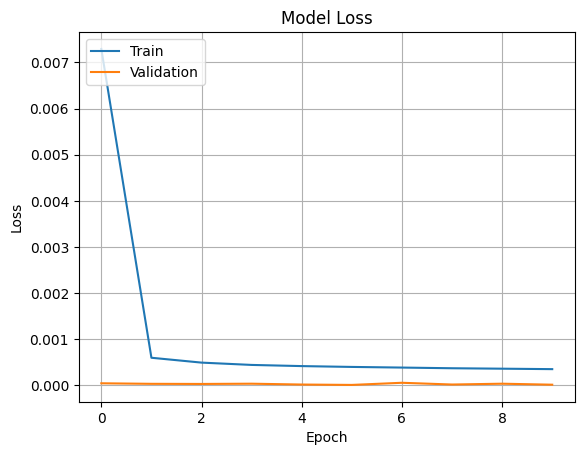

C:\Users\ymarc\AppData\Local\Temp\ipykernel_60500\3697874067.py:81: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


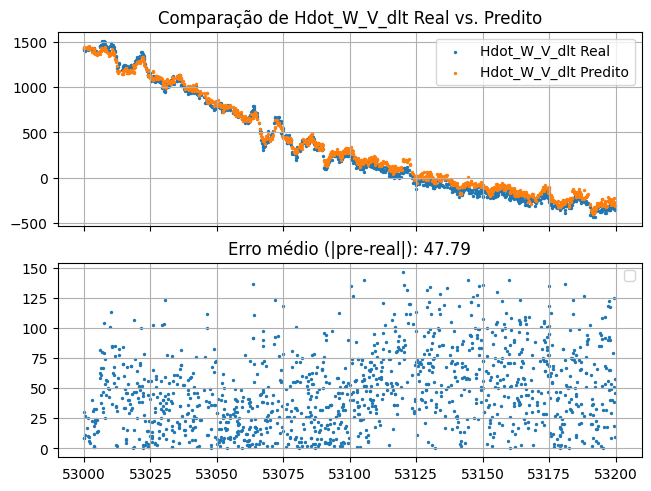

In [50]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='',
    features1=['Mach', 'N1_over_sqrt_theta'],
    features2=['Mach2', 'NZ_W_dlt_sqr'],
    targets=['Hdot_W_V_dlt'],
    mode='train',
    architecture={
        'neurons': 50,
        'camadas_ocultas': 3,
        'activation': 'relu',
        'dropout': 0
    },
    hyperparameters={
        'optimizer': 'adam',
        'learning_rate': 0.0001,
        'epochs': 100,
        'batch_size': 32,
        'patience': 4,
        'lambda_mono': 0.13,  # peso da penalidade d(Z1)/d(NG) < 0 (opção 2 / PINN)
    }
)

In [51]:
# Modelo que expõe Z1 e Z2 além da saída final
extractor = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer('NN1_output').output,  # Z1
        model.get_layer('NN2_output').output,  # Z2
        model.output                           # Y (Z1 - Z2)
    ]
)

In [52]:
features1 = ['Mach', 'N1_over_sqrt_theta']
features2 = ['Mach2', 'NZ_W_dlt_sqr']

features1_scaled = [f + '_scaled' for f in features1]
features2_scaled = [f + '_scaled' for f in features2]

X1_all = np.array(df[features1_scaled]).astype(np.float32)
X2_all = np.array(df[features2_scaled]).astype(np.float32)

z1_vals, z2_vals, y_vals = extractor.predict([X1_all, X2_all])

# Adiciona ao DataFrame (ainda em escala normalizada)
df['Z1_scaled'] = z1_vals.flatten()
df['Z2_scaled'] = z2_vals.flatten()

3377/3377 ━━━━━━━━━━━━━━━━━━━━ 2s 569us/step


In [53]:
df['Z1'] = scaler_y.inverse_transform(z1_vals).flatten()
df['Z2'] = scaler_y.inverse_transform(z2_vals).flatten()
# df['Z1'] = z1_vals.flatten()
# df['Z2'] = z2_vals.flatten()

# z1_minus_z2_vals = (z1_vals - z2_vals)
# df['Z1_minus_Z2'] = z1_minus_z2_vals.flatten()
df['Z1_minus_Z2'] = scaler_y.inverse_transform(y_vals).flatten()

In [54]:
def mase_pointwise(y_pred, y_true):
    """
    Erro ponto a ponto normalizado pelo naive forecast (passo anterior de y_true).
    Retorna array com mesma forma de y_true.
    """
    naive_mae = np.mean(np.abs(np.diff(y_true)))  # denominador escalar
    if naive_mae == 0:
        return np.full(len(y_true), np.nan)
    return np.abs(y_pred - y_true) / naive_mae

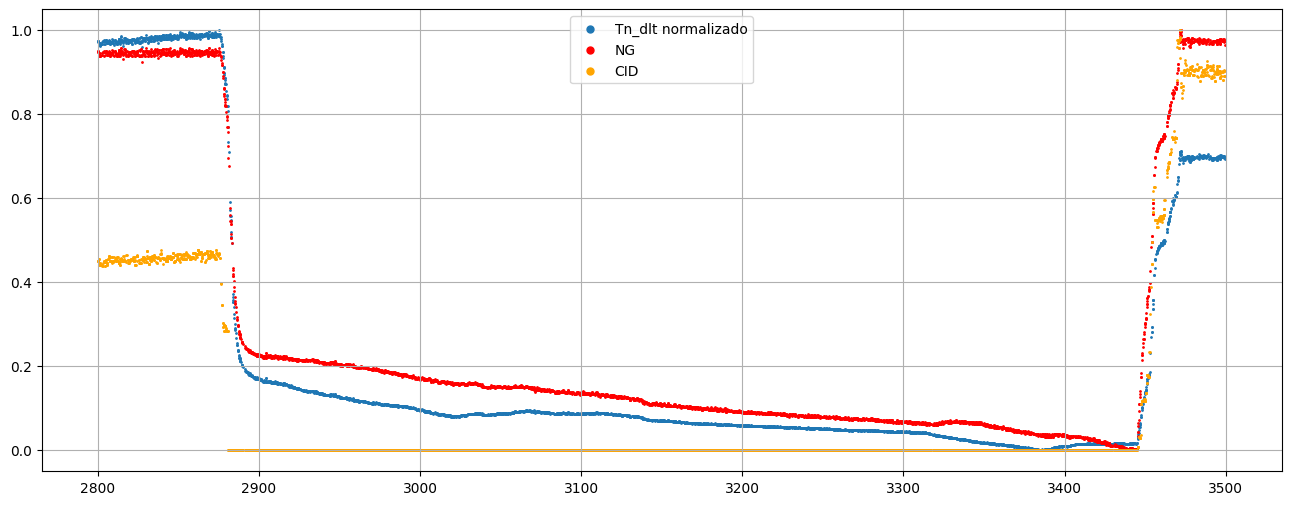

In [55]:
df_teste = split_train_test_val(make_df('completo'))

# df_teste = df_teste[df_teste['filename'].str.contains('040')].copy()
df_teste = df_teste[df_teste['type'] == 'test'].copy()

df_teste['Tn_dlt'] = (df_teste['T'] * cos(np.radians(df_teste['Alfa'])) / df_teste['delta']) * 0.453592
df_teste['D_dlt'] = df_teste['Tn_dlt'] - df_teste['Hdot_W_V_dlt']

mask = df_teste['TEMPO_SAD'].between(2800, 3500)
df_teste = df_teste[mask]

plt.figure(figsize=(16, 6))
plt.scatter(df_teste['TEMPO_SAD'], (df_teste['Tn_dlt']- min(df_teste['Tn_dlt'])) / (max(df_teste['Tn_dlt']) - min(df_teste['Tn_dlt'])), s=1, label='Tn_dlt normalizado')
plt.scatter(df_teste['TEMPO_SAD'], (df_teste['NG'] - min(df_teste['NG'])) / (max(df_teste['NG']) - min(df_teste['NG'])), s=1, color='red', label='NG')
plt.scatter(df_teste['TEMPO_SAD'], (df_teste['CID'] - min(df_teste['CID'])) / (max(df_teste['CID']) - min(df_teste['CID'])), s=1, color='orange', label='CID')
plt.legend(markerscale=5)
# plt.xlim(5e4, 6e4)
plt.grid()
plt.show()

# plt.figure(figsize=(16, 6))
# plt.scatter(df_teste['TEMPO_SAD'], df_teste['Alfa'], s=1, label='Alfa')
# plt.legend(markerscale=5)
# # plt.xlim(5e4, 6e4)
# plt.grid()
# plt.show()

# plt.figure(figsize=(16, 6))
# plt.scatter(df_teste['NZ_W_dlt'], df_teste['D_dlt'], s=1, label='Polar de arrasto')
# plt.legend(markerscale=5)
# plt.grid()
# plt.show()

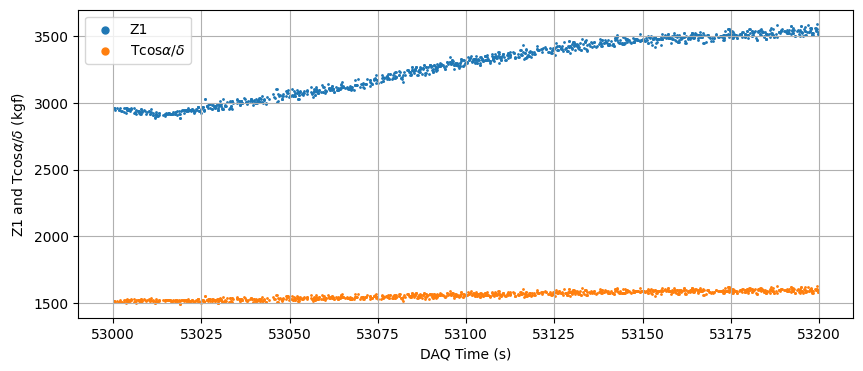

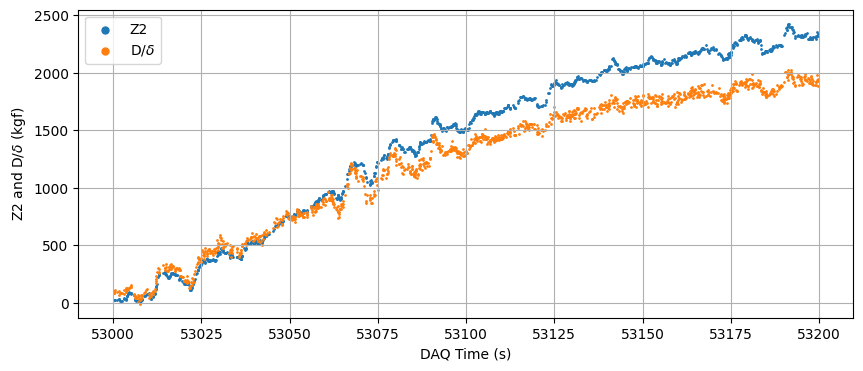

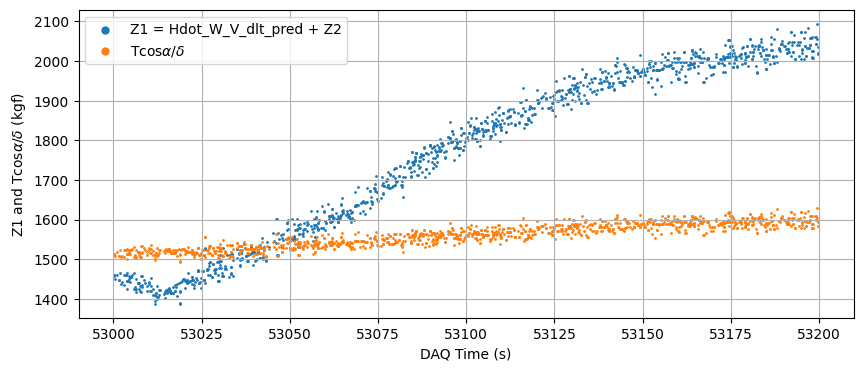

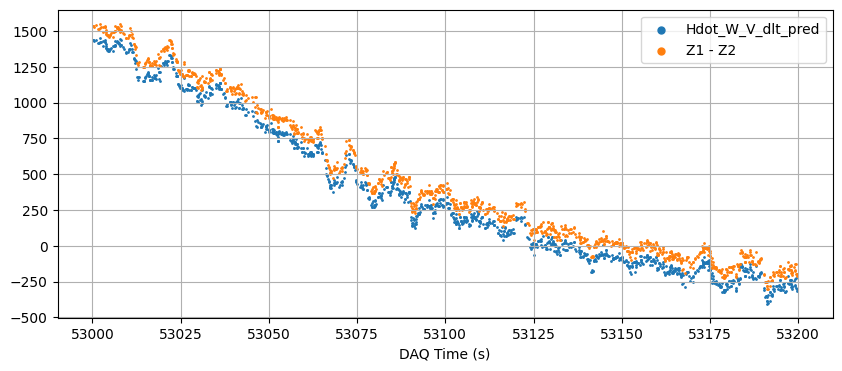

10755.183


In [83]:
evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

df['Tn_dlt'] = ( df['T']*cos(np.radians(df['Alfa']))/df['delta'] ) * 0.453592 # Tração normal, em kgf
df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    # t0, t = 2000, 2500
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    erro_mase = mase_pointwise(grupo['Z1'].values, grupo['Tn_dlt'].values)

    k = 750

    plt.figure(figsize=(10,4))
    # plt.scatter(grupo['TEMPO_SAD'], (grupo['Z1'] - min(grupo['Z1'])) / (max(grupo['Z1']) - min(grupo['Z1'])), s=dot_size, label='Z1 normalizado')
    # plt.scatter(grupo['TEMPO_SAD'], (grupo['Tn_dlt'] - min(grupo['Tn_dlt'])) / (max(grupo['Tn_dlt']) - min(grupo['Tn_dlt'])), s=dot_size, label=r'Tcos$\alpha$/$\delta$ normalizado')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1']+k-10755.183, s=dot_size, label='Z1')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
    plt.legend(markerscale=5)
    # plt.xlim()
    plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    # plt.xlim(2000, 2500)
    plt.show()

    plt.figure(figsize=(10,4))
    # plt.scatter(grupo['TEMPO_SAD'], (grupo['Z2'] - min(grupo['Z2'])) / (max(grupo['Z2']) - min(grupo['Z2'])), s=dot_size, label='Z2 normalizado')
    # plt.scatter(grupo['TEMPO_SAD'], (grupo['D_dlt'] - min(grupo['D_dlt'])) / (max(grupo['D_dlt']) - min(grupo['D_dlt'])), s=dot_size, label=r'D/$\delta$ normalizado')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z2']-k, s=dot_size, label='Z2')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label=r'D/$\delta$')    
    plt.legend(markerscale=5)
    # plt.xlim(600, 1500)
    plt.ylabel(r'Z2 and D/$\delta$ (kgf)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    # plt.xlim(2000, 2500)
    plt.show()


    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'] + grupo['Z2'] -k, s=dot_size, label='Z1 = Hdot_W_V_dlt_pred + Z2')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label=r'Tcos$\alpha$/$\delta$')
    plt.legend(markerscale=5)
    # plt.xlim()
    plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ (kgf)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    # plt.xlim(2000, 2500)
    plt.show()

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_pred'], s=dot_size, label='Hdot_W_V_dlt_pred')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1']-grupo['Z2'] - 10755.183 + 100, s=dot_size, label=r'Z1 - Z2')
    # plt.scatter(grupo['TEMPO_SAD'], abs(grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1']-grupo['Z2'])), s=dot_size, label=r'difference')
    plt.legend(markerscale=5)
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    # plt.xlim(2000, 2500)
    plt.show()

    print((abs(grupo['Hdot_W_V_dlt_pred'] - (grupo['Z1']-grupo['Z2'])).mean()))

In [36]:
df['Vdot'] = None
df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Vdot'] = savgol_filter(
    df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'Va']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.5144


evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

subset = df[df['type'] == evaluated_set]

df['Tn_dlt'] = ( df['T']*cos(np.radians(df['Alfa_filtered']))/df['delta'] ) * 0.453592 # Tração normal, em kgf
df['D_dlt'] = df['Tn_dlt'] - df['Hdot_W_V_dlt']

df['Z1_dot_trend'] = None
df['Tn_dlt_dot_trend'] = None

df['Z2_dot_trend'] = None
df['D_dlt_dot_trend'] = None

n=501
grau=2
T = 1/32

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    grupo['Z1_dot_trend'] = savgol_filter(
        grupo['Z1'], window_length=n, polyorder=grau, deriv=1, delta=T
    )
    grupo['Tn_dlt_dot_trend'] = savgol_filter(
        grupo['Tn_dlt'], window_length=n, polyorder=grau, deriv=1, delta=T
    )

    # erro_relativo = abs((grupo['Z1_dot_trend'] - grupo['Tn_dlt_dot_trend']) / grupo['Tn_dlt_dot_trend']) * 100

    erro_mase = mase_pointwise(
        grupo['Z1_dot_trend'].values,
        grupo['Tn_dlt_dot_trend'].values
    )

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z1_dot_trend'], s=dot_size, label='d(Z1)/dt')
    plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt_dot_trend'], s=dot_size, label=r'd(Tcos$\alpha$/$\delta$)/dt')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    plt.ylabel(r'Z1 and Tcos$\alpha$/$\delta$ derivatives (kgf/s)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], erro_mase, s=dot_size, label='Z1')
    plt.title(f'MASE médio: {np.nanmean(erro_mase):.4f}')
    plt.ylabel('MASE (adimensional)')
    # plt.ylim(0, 5)  # ajuste conforme necessário
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()
for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    grupo['Z2_dot_trend'] = savgol_filter(
        grupo['Z2'], window_length=n, polyorder=grau, deriv=1, delta=T
    )
    grupo['D_dlt_dot_trend'] = savgol_filter(
        grupo['D_dlt'], window_length=n, polyorder=grau, deriv=1, delta=T
    )

    # erro_relativo = abs((grupo['Z2_dot_trend'] - grupo['D_dlt_dot_trend']) / grupo['D_dlt_dot_trend']) * 100
    erro_mase = mase_pointwise(
        grupo['Z2_dot_trend'].values,
        grupo['D_dlt_dot_trend'].values
    )
    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], grupo['Z2_dot_trend'], s=dot_size, label=r'd(Z2)/dt')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt_dot_trend'], s=dot_size, label=r'd(D/$\delta$)/dt')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    plt.ylabel(r'Z2 and D/$\delta$ derivatives (kgf/s)')
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

    plt.figure(figsize=(10,4))
    plt.scatter(grupo['TEMPO_SAD'], erro_mase, s=dot_size, label='Z2')
    plt.title(f'MASE médio: {np.nanmean(erro_mase):.4f}')
    plt.ylabel('MASE (adimensional)')
    # plt.ylim(0, 5)
    plt.xlabel('DAQ Time (s)')
    plt.grid()
    plt.show()

NameError: name 'n' is not defined

In [38]:
df_teste = make_df('completo')

n=501
grau=2
# T = df.loc[(df['TEMPO_SAD']>t0) & (df['TEMPO_SAD']<t), 'TEMPO_SAD'].diff().mean() # Taxa de aquisição: aproximadamente 32 Hz, o que é consistente com os dados de tempo fornecidos
T = 1/32
g = 9.81
df_teste['Vdot'] = savgol_filter(
    df_teste['Va']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.5144

df_teste['hdot'] = savgol_filter(
    df_teste['Zp']
    , window_length=n, polyorder=grau, deriv=1, delta=T)*0.3048

df_teste['Hdot_W_V_dlt_2nd_approach'] = (df_teste['hdot'] + df_teste['Va']*df_teste['Vdot']/g)*df_teste['W']/(df_teste['Va']*df_teste['delta'])


evaluated_set = 'test'
dot_size = 1

time_intervals = {
        '039_2013_VIN_FND': (5e4, 7e4),
        '040_2013_ASO_VTO': (0, 5e4),
        '041_2013_GEO_AIR': (0, 1e5),
        '042_2013_VAU_FTR': (0, 8e4)
    }

df_teste['Tn_dlt'] = ( df_teste['T']*cos(np.radians(df_teste['Alfa']))/df_teste['delta'] ) * 0.453592 # Tração normal, em kgf
df_teste['D_dlt'] = df_teste['Tn_dlt'] - df_teste['Hdot_W_V_dlt']

df_teste['Tn_dlt_2nd_approach'] = ( df_teste['T']*cos(np.radians(df_teste['Alfa']))/df_teste['delta'] ) * 0.453592 # Tração normal, em kgf
df_teste['D_dlt_2nd_approach'] = df_teste['Tn_dlt_2nd_approach'] - df_teste['Hdot_W_V_dlt_2nd_approach']

subset = df_teste[df_teste['filename'] == '040_2013_ASO_VTO']

for filename, grupo in subset.groupby('filename'):

    t0, t = time_intervals[filename]
    mask = (grupo['TEMPO_SAD'] > t0) & (grupo['TEMPO_SAD'] < t)
    grupo = grupo[mask]

    plt.figure(figsize=(16,6))
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt'], s=dot_size, label='Tn/dlt')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Tn_dlt_2nd_approach'], s=dot_size, label='Tn/dlt_2nd_approach')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt'], s=dot_size, label='D/dlt')
    plt.scatter(grupo.loc[grupo['D_dlt']<0, 'TEMPO_SAD'], grupo.loc[grupo['D_dlt']<0, 'D_dlt'], s=dot_size, label='D/dlt<0')
    plt.scatter(grupo['TEMPO_SAD'], grupo['D_dlt_2nd_approach'], s=dot_size, label='D/dlt_2nd_approach')
    plt.scatter(grupo.loc[grupo['D_dlt_2nd_approach']<0, 'TEMPO_SAD'], grupo.loc[grupo['D_dlt_2nd_approach']<0, 'D_dlt_2nd_approach'], s=dot_size, label='D/dlt_2nd_approach<0')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt'], s=dot_size, label='Hdot_W_V_dlt')
    # plt.scatter(grupo['TEMPO_SAD'], grupo['Hdot_W_V_dlt_2nd_approach'], s=dot_size, label='Hdot_W_V_dlt_2nd_approach')
    plt.legend(markerscale=5)
    # plt.ylim(-10,10)
    # plt.ylabel(r'Z1 e T/$\delta$ (kgf)')
    plt.ylabel('Hdot/V * W/delta')
    plt.xlabel('TEMPO_SAD (s)')
    plt.grid()

    plt.show()

## Modelo auxiliar: CID corrigido — f(Mach, NZ/sqrt(theta))

Rede densa simples (não usa a arquitetura Z1-Z2). Prevê `CID/(delta*sqrt(theta))` a partir de `Mach` e `NZ/sqrt(theta)`, com split, scaler e treino próprios.

In [17]:
# =========================================================
# Modelo auxiliar: CID/(delta*sqrt(theta)) = f(Mach, NZ/sqrt(theta))
# Rede unica (nao-siamese), com arquitetura, split e scaler proprios.
# =========================================================

# --- Features derivadas ---
df = make_df('completo')

# df = df[df['filename'].isin(['039_2013_VIN_FND'])]

# # mask_leveled_acceleration = (
# #     ((df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 52625)) +
# #     ((df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53200)) +
# #     ((df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54075)) +
# #     ((df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55100))
# # )
# mask_leveled_acceleration = (
#     ((df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 53000)) +
#     ((df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53775)) +
#     ((df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54750)) +
#     ((df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55400))
# )

# df = df[mask_leveled_acceleration]

# df.loc[(df['TEMPO_SAD'] > 52400) & (df['TEMPO_SAD'] < 53000), 'faixa_altitude'] = 'A'
# df.loc[(df['TEMPO_SAD'] > 53000) & (df['TEMPO_SAD'] < 53775), 'faixa_altitude'] = 'B'
# df.loc[(df['TEMPO_SAD'] > 53775) & (df['TEMPO_SAD'] < 54750), 'faixa_altitude'] = 'C'
# df.loc[(df['TEMPO_SAD'] > 54750) & (df['TEMPO_SAD'] < 55400), 'faixa_altitude'] = 'D'

df['NG_over_sqrt_theta'] = df['NG'] / np.sqrt(df['theta'])
df['CID_corr'] = df['CID'] / (df['delta'] * np.sqrt(df['theta']))

features_cid = ['Mach', 'NG_over_sqrt_theta']
target_cid   = ['CID_corr']


def build_model_cid(features, architecture={}, hyperparameters={}):
    """
    Rede densa simples: recebe [Mach, NG/sqrt(theta)] e preve
    CID/(delta*sqrt(theta)) diretamente (sem sub-redes Z1/Z2).
    """
    neurons      = architecture.get('neurons', 16)
    n_hidden     = architecture.get('camadas_ocultas', 1)
    activation   = architecture.get('activation', 'relu')
    dropout_rate = architecture.get('dropout', 0.0)

    optimizer_name = hyperparameters.get('optimizer', 'adam')
    learning_rate  = hyperparameters.get('learning_rate', 0.001)
    epochs         = hyperparameters.get('epochs', 100)
    batch_size     = hyperparameters.get('batch_size', 32)
    patience       = hyperparameters.get('patience', 3)

    input_layer = layers.Input(shape=(len(features),), name='Entrada_CID')
    x = input_layer
    for i in range(n_hidden):
        x = layers.Dense(neurons, activation=activation, name=f'CID_hidden_{i+1}')(x)
        if dropout_rate > 0:
            x = layers.Dropout(dropout_rate, name=f'CID_dropout_{i+1}')(x)
    output = layers.Dense(1, name='CID_output')(x)

    model = Model(inputs=input_layer, outputs=output)

    optimizer = keras.optimizers.get({
        'class_name': optimizer_name,
        'config': {'learning_rate': learning_rate}
    })
    model.compile(optimizer=optimizer, loss='mse')

    model.epochs     = epochs
    model.batch_size = batch_size
    model.patience   = patience

    return model


def scale_data_cid(df, features, targets):
    scaler_x = MinMaxScaler()
    scaler_y = MinMaxScaler()

    df[[p + '_scaled' for p in features]] = None
    df[[p + '_scaled' for p in targets]]  = None

    for split, method in [('train', 'fit_transform'), ('test', 'transform'), ('val', 'transform')]:
        mask = df['type'] == split
        df.loc[mask, [p + '_scaled' for p in features]] = getattr(scaler_x, method)(df.loc[mask, features])
        df.loc[mask, [p + '_scaled' for p in targets]]  = getattr(scaler_y, method)(df.loc[mask, targets])

    return df, scaler_x, scaler_y


def train_model_cid(df, features, targets, model, hyperparameters):
    features_scaled = [f + '_scaled' for f in features]
    targets_scaled  = [t + '_scaled' for t in targets]

    X_train = np.array(df.loc[df['type'] == 'train', features_scaled]).astype(np.float32)
    X_val   = np.array(df.loc[df['type'] == 'val',   features_scaled]).astype(np.float32)
    Y_train = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32)
    Y_val   = np.array(df.loc[df['type'] == 'val',   targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience'],
        restore_best_weights=True
    )

    print("Treinando modelo CID...")
    training_history = model.fit(
        X_train, Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=(X_val, Y_val),
        verbose=1
    )
    joblib.dump(training_history, './trainHistoryDict_CID.pkl')
    model.save('./model_CID.keras')

    return model, training_history


def pipeline_cid(df, features, targets, architecture, hyperparameters):
    df = split_train_test_val(df)  # reaproveita a logica de split (faixa_altitude == 'B' -> test)
    df, scaler_x, scaler_y = scale_data_cid(df, features, targets)

    model = build_model_cid(features, architecture, hyperparameters)
    model, training_history = train_model_cid(df, features, targets, model, hyperparameters)

    return df, scaler_x, scaler_y, model, training_history


In [30]:
def plotgraphs(model_cid, training_history_cid, df):
    plt.plot(training_history_cid.history['loss'])
    plt.plot(training_history_cid.history['val_loss'])
    plt.title('Model Loss - CID')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.show()

    # =========================================================
    # Comparação CID_corr: Real vs. Predito
    # =========================================================

    features_cid_scaled = [f + '_scaled' for f in features_cid]
    X_cid_all = np.array(df[features_cid_scaled]).astype(np.float32)

    pred_scaled_cid = model_cid.predict(X_cid_all)
    df['CID_corr_pred'] = scaler_y_cid.inverse_transform(pred_scaled_cid).flatten()

    # plt.show()
    for evaluated_set in ['train', 'test']:
        subset = df[df['type'] == evaluated_set]

        erro_relativo_cid = (subset['CID_corr_pred'] - subset['CID_corr']) / subset['CID_corr'].abs() * 100
        erro_medio_cid = np.nanmean(np.abs(erro_relativo_cid))

        fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)

        axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr'], s=1, label='CID_corr Real')
        axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr_pred'], s=1, label='CID_corr Predito')
        axes[0].set_ylabel('CID_corr')
        axes[0].set_title(f'CID_corr Real vs. Predito (set={evaluated_set}) — Erro médio: {erro_medio_cid:.2f}%')
        axes[0].legend(markerscale=5)
        axes[0].grid()

        axes[1].scatter(subset['TEMPO_SAD'], erro_relativo_cid, s=1, color='tab:orange')
        axes[1].set_ylabel('Erro relativo (%)')
        axes[1].set_xlabel('TEMPO_SAD (s)')
        axes[1].grid()

        plt.show()

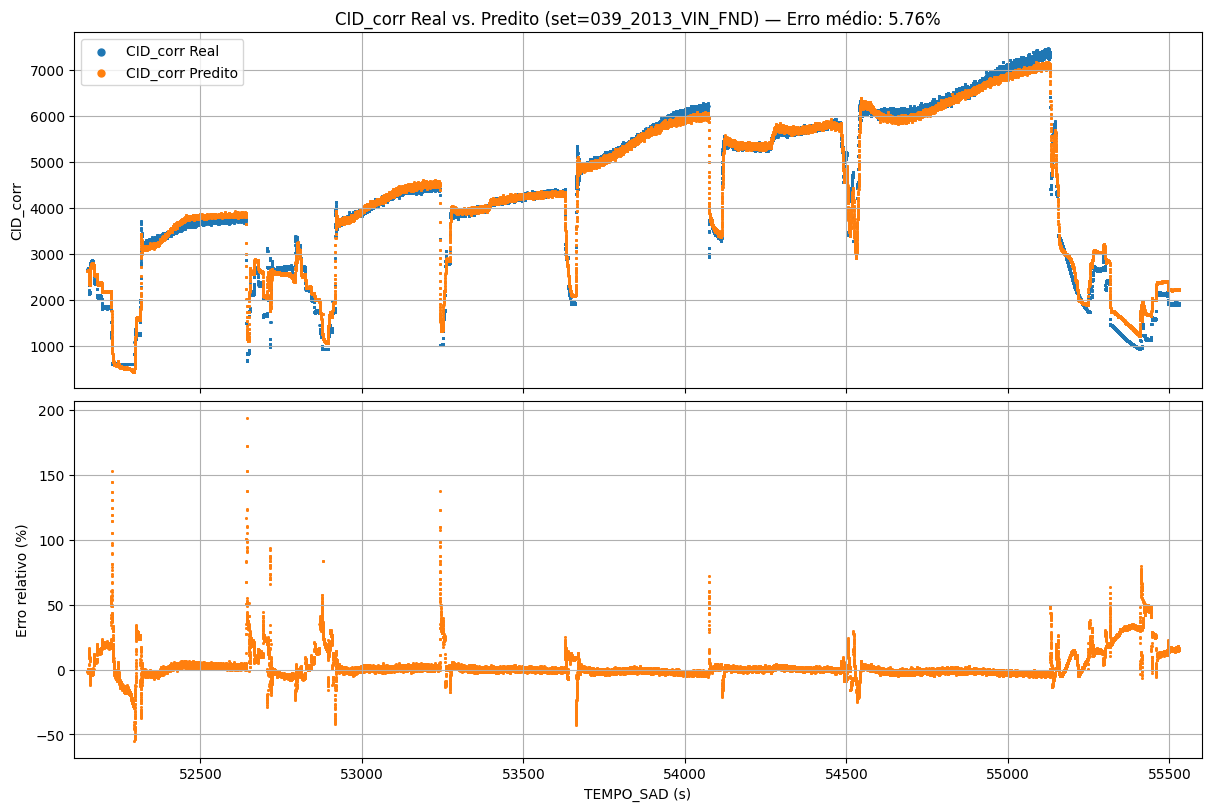

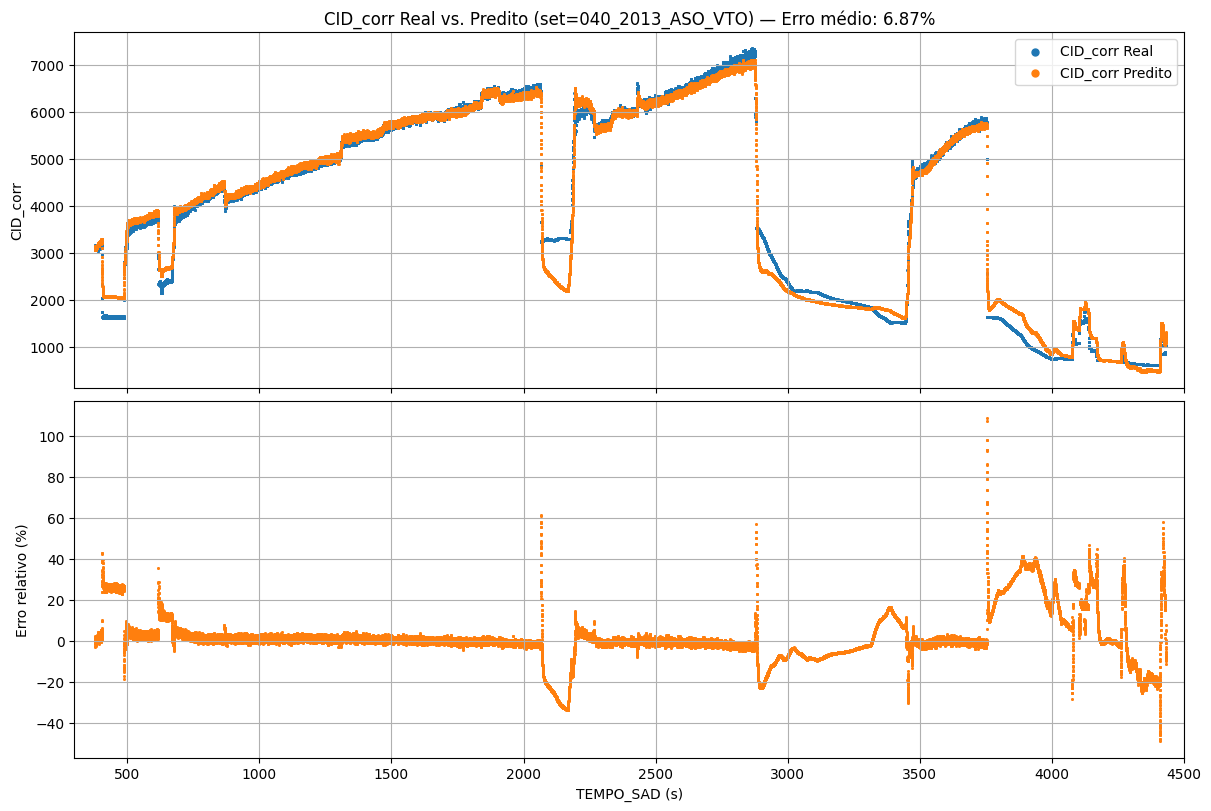

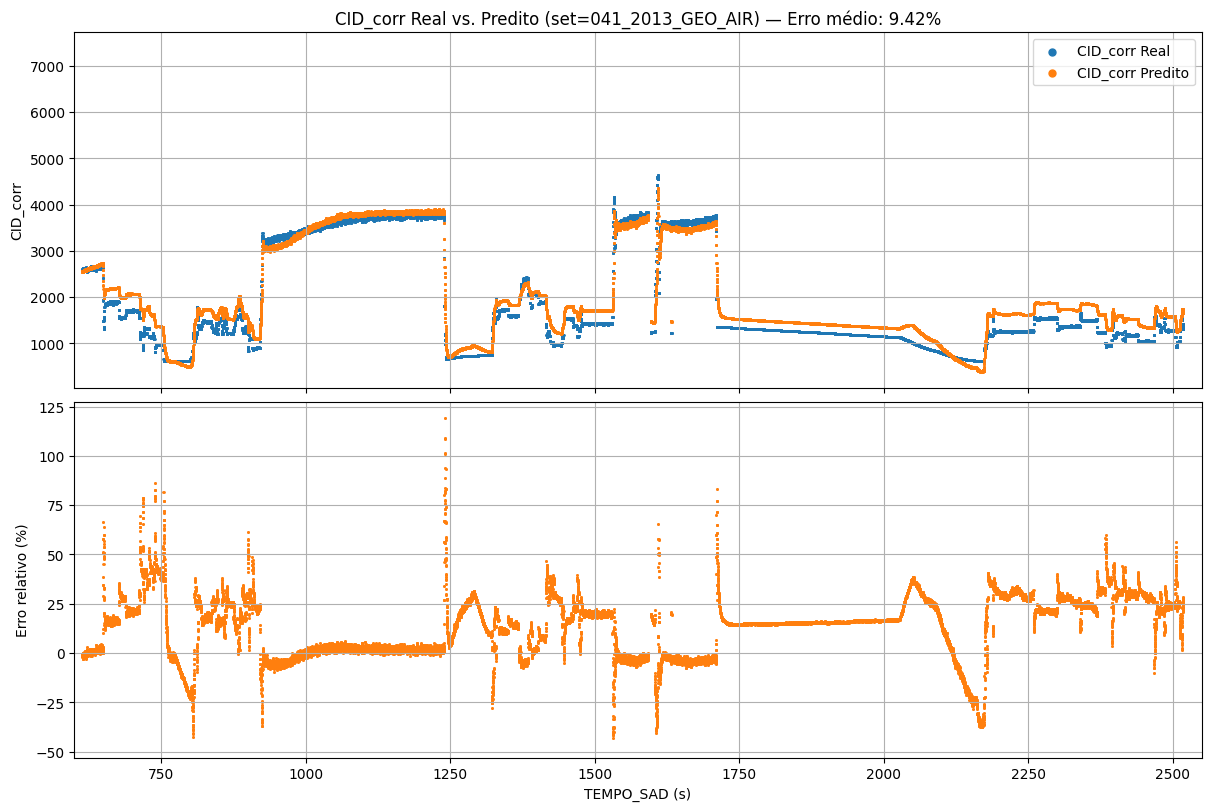

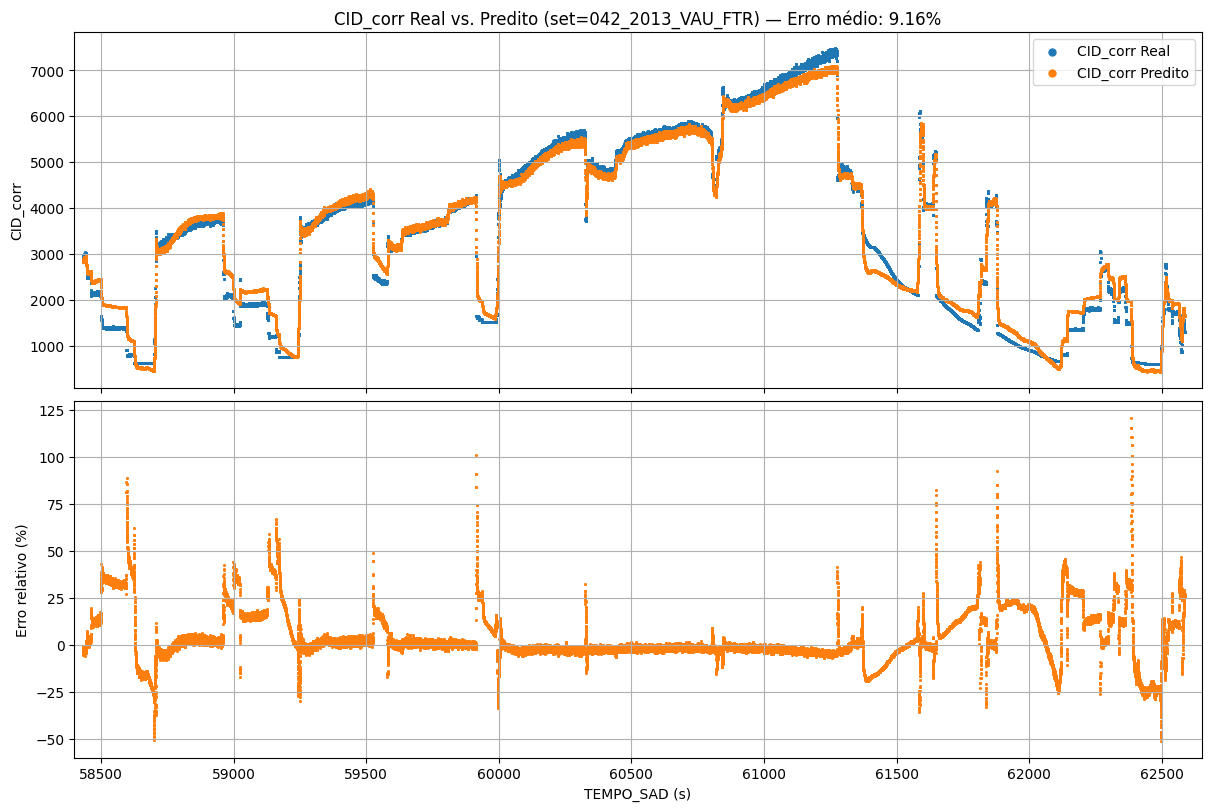

In [ ]:
# Gráficos de treinamento
for i, arquive_name in enumerate(['039_2013_VIN_FND', '040_2013_ASO_VTO', '041_2013_GEO_AIR', '042_2013_VAU_FTR']):
        faixas = ['A', 'B', 'C', 'D']
        subset = df[df['faixa_altitude'] == faixas[i]]
        ranges = [
                (52110, 55600),
                (300, 4500),
                (600, 2550),
                (58400, 62650)
        ]

        erro_relativo_cid = (subset['CID_corr_pred'] - subset['CID_corr']) / subset['CID_corr'].abs() * 100
        erro_medio_cid = np.nanmean(np.abs(erro_relativo_cid))

        fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
        # fig, axes = plt.subplots(1, 1, figsize=(6, 4), sharex=True, constrained_layout=True)

        axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr'], s=1, label='CID_corr Real')
        axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr_pred'], s=1, label='CID_corr Predito')
        axes[0].set_ylabel('CID_corr')
        axes[0].set_title(f'CID_corr Real vs. Predito (set={arquive_name}) — Erro médio: {erro_medio_cid:.2f}%')
        axes[0].legend(markerscale=5)
        axes[0].set_xlim(ranges[i])
        axes[0].grid()

        axes[1].scatter(subset['TEMPO_SAD'], erro_relativo_cid, s=1, color='tab:orange')
        axes[1].set_ylabel('Erro relativo (%)')
        axes[1].set_xlabel('TEMPO_SAD (s)')
        axes[1].grid()

        plt.show()

Treinando modelo CID...


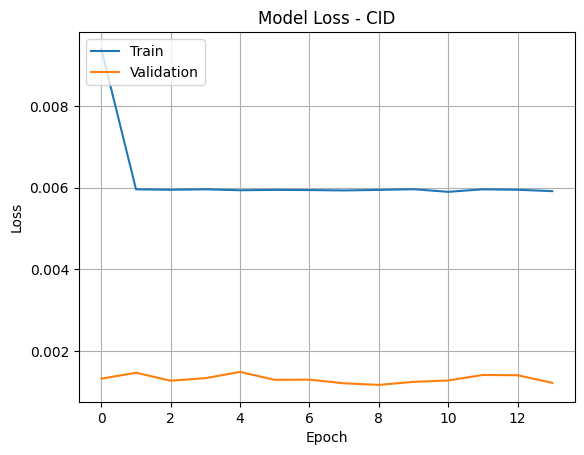

16120/16120 ━━━━━━━━━━━━━━━━━━━━ 7s 409us/step


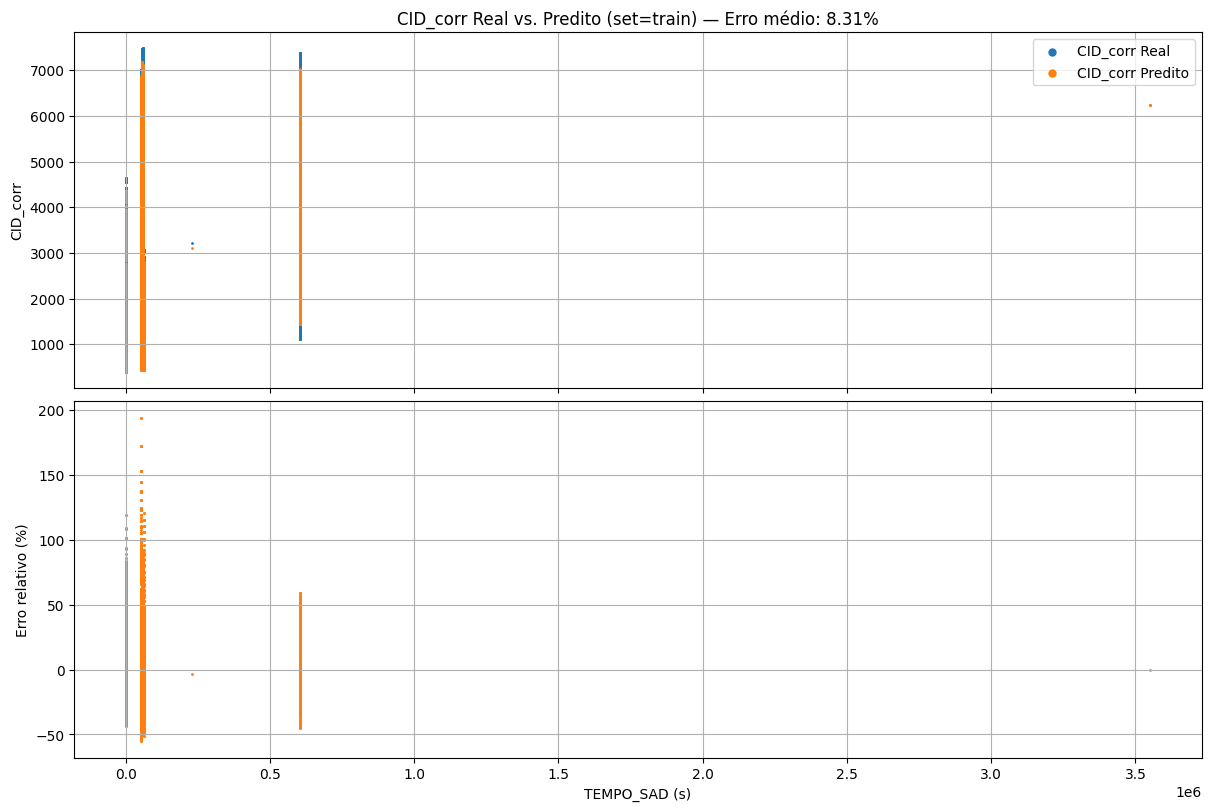

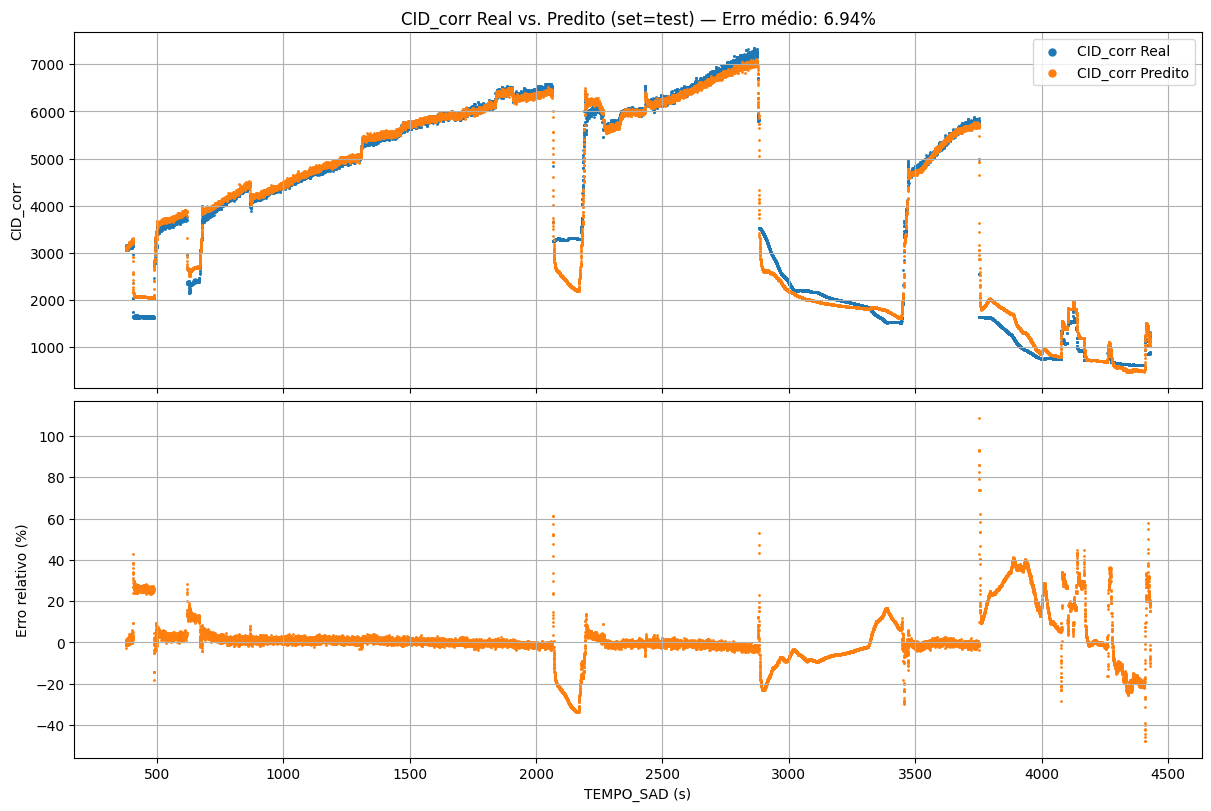

In [31]:
architecture_cid = {
    'neurons': 16,
    'camadas_ocultas': 1,
    'activation': 'relu',
    'dropout': 0.2
}
hyperparameters_cid = {
    'optimizer': 'adam',
    'learning_rate': 0.001,
    'epochs': 150,
    'batch_size': 64,
    'patience': 5
}
df, scaler_x_cid, scaler_y_cid, model_cid, training_history_cid = pipeline_cid(
    df, features_cid, target_cid, architecture_cid, hyperparameters_cid
)
plotgraphs(model_cid, training_history_cid, df)

Treinando modelo CID...


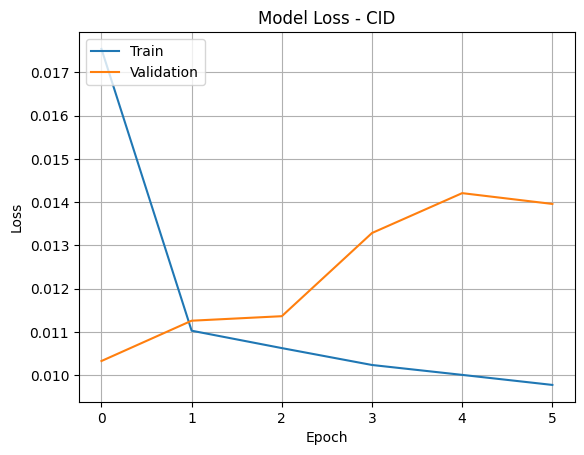

16120/16120 ━━━━━━━━━━━━━━━━━━━━ 9s 529us/step


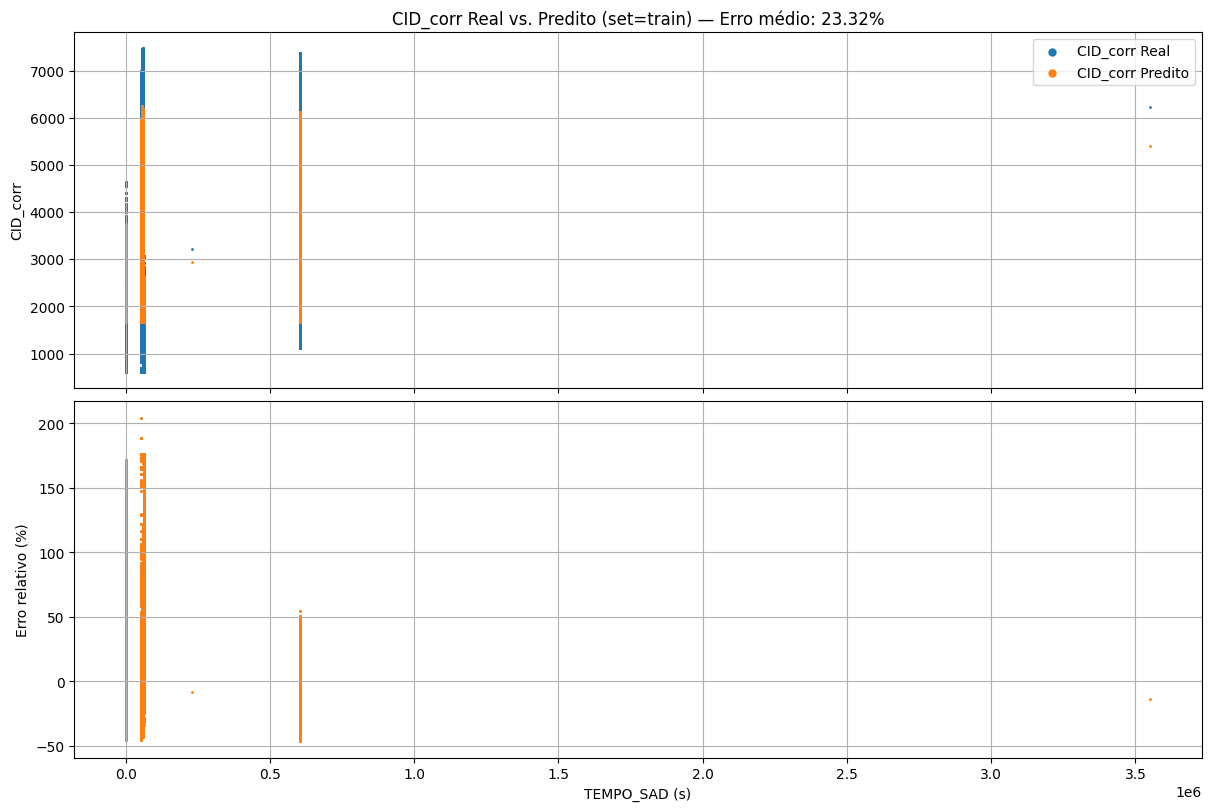

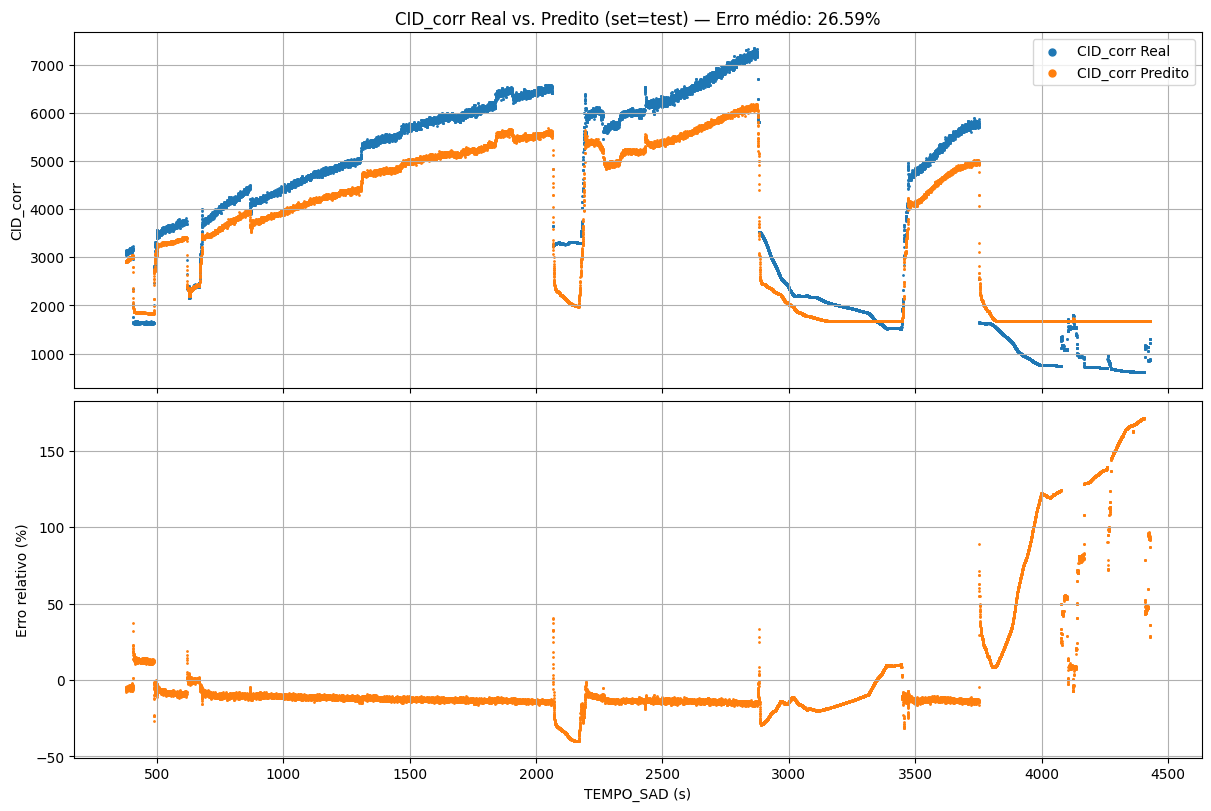

In [43]:
architecture_cid = {
    'neurons': 16,
    'camadas_ocultas': 2,
    'activation': 'relu',
    'dropout': 0.2
}
hyperparameters_cid = {
    'optimizer': 'adam',
    'learning_rate': 0.001,
    'epochs': 150,
    'batch_size': 64,
    'patience': 5
}
df, scaler_x_cid, scaler_y_cid, model_cid, training_history_cid = pipeline_cid(
    df, features_cid, target_cid, architecture_cid, hyperparameters_cid
)
plotgraphs(training_history_cid, df)

Treinando modelo CID...


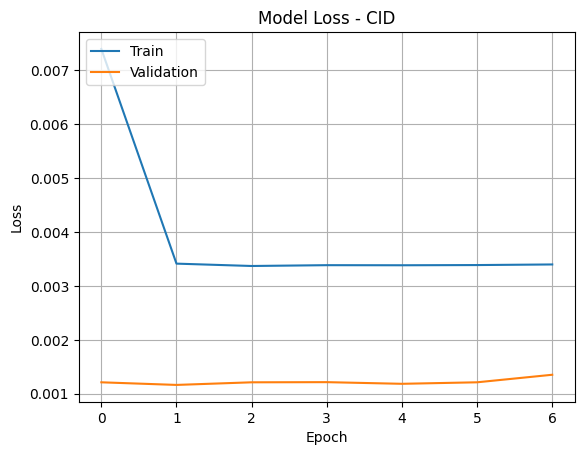

16120/16120 ━━━━━━━━━━━━━━━━━━━━ 8s 492us/step


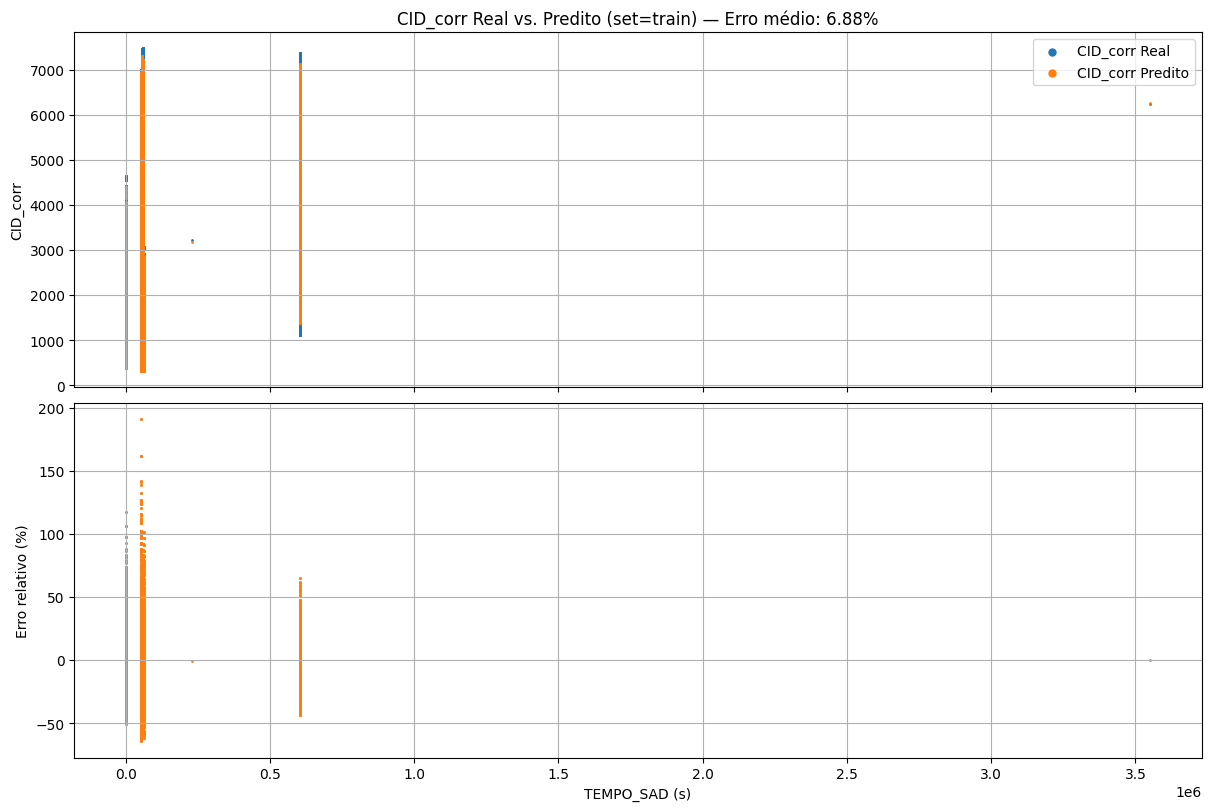

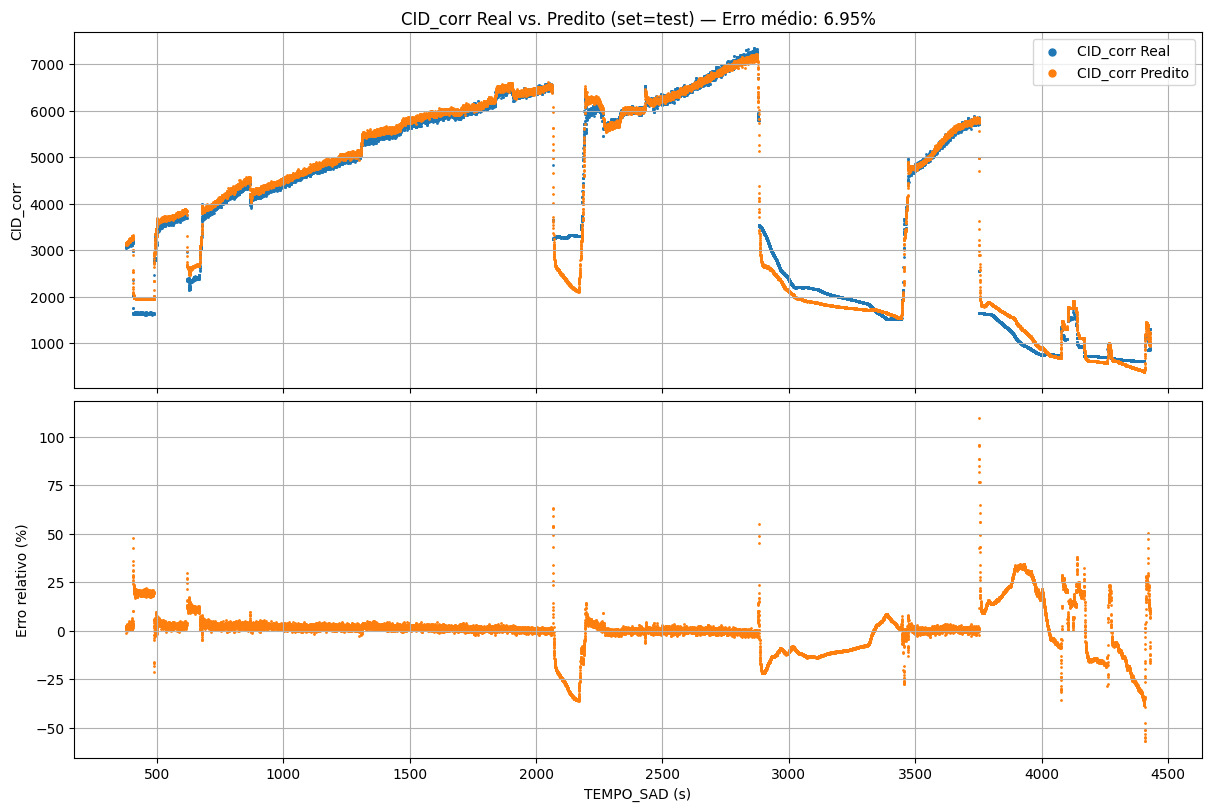

In [44]:
architecture_cid = {
    'neurons': 32,
    'camadas_ocultas': 1,
    'activation': 'relu',
    'dropout': 0.2
}
hyperparameters_cid = {
    'optimizer': 'adam',
    'learning_rate': 0.001,
    'epochs': 150,
    'batch_size': 64,
    'patience': 5
}
df, scaler_x_cid, scaler_y_cid, model_cid, training_history_cid = pipeline_cid(
    df, features_cid, target_cid, architecture_cid, hyperparameters_cid
)
plotgraphs(training_history_cid, df)

Treinando modelo CID...


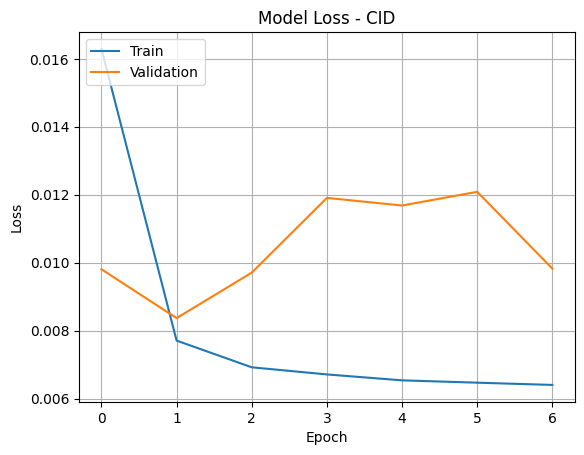

16120/16120 ━━━━━━━━━━━━━━━━━━━━ 10s 641us/step


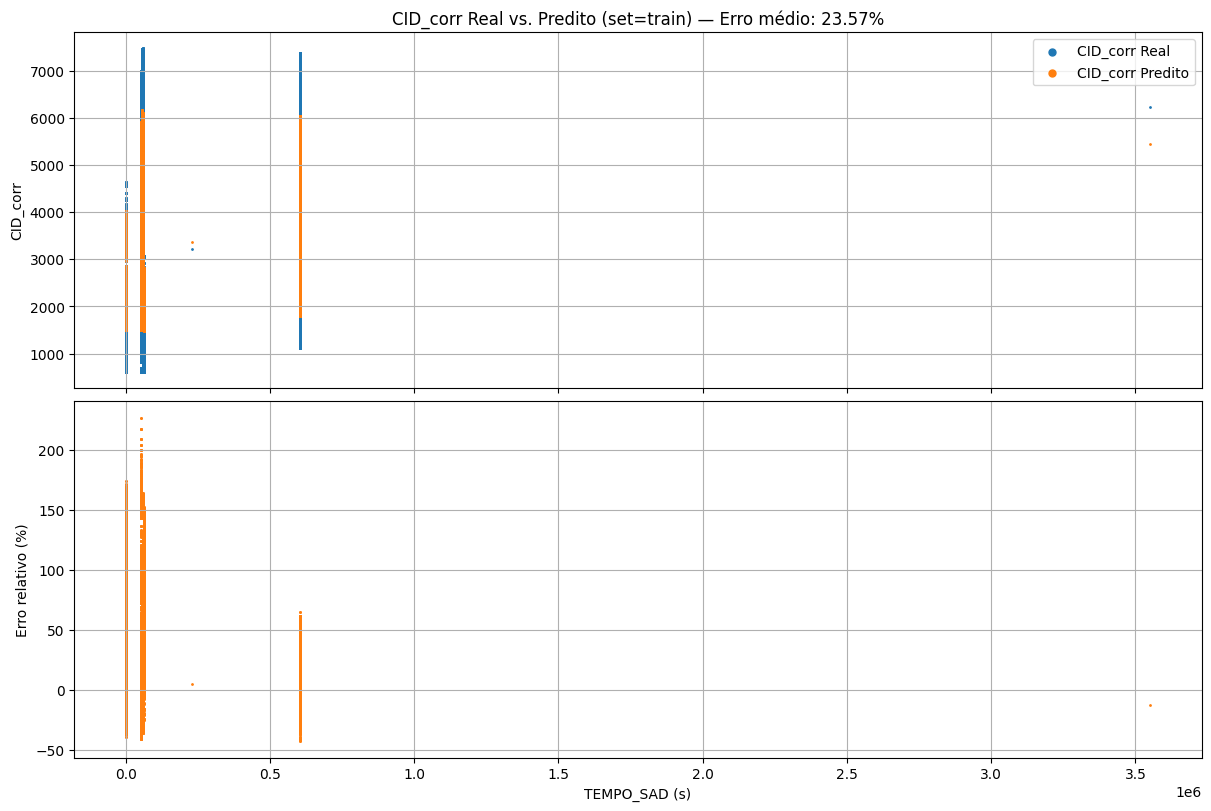

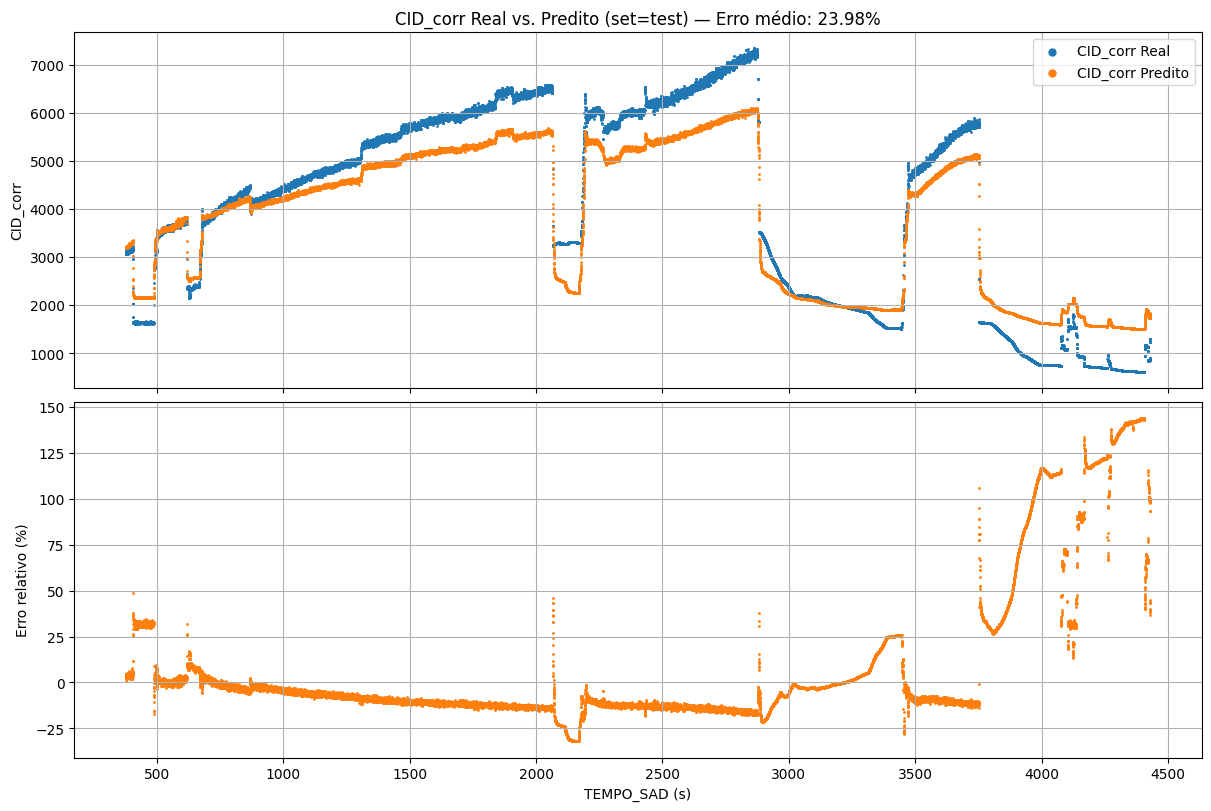

In [45]:
architecture_cid = {
    'neurons': 16,
    'camadas_ocultas': 3,
    'activation': 'relu',
    'dropout': 0.2
}
hyperparameters_cid = {
    'optimizer': 'adam',
    'learning_rate': 0.001,
    'epochs': 150,
    'batch_size': 64,
    'patience': 5
}
df, scaler_x_cid, scaler_y_cid, model_cid, training_history_cid = pipeline_cid(
    df, features_cid, target_cid, architecture_cid, hyperparameters_cid
)
plotgraphs(training_history_cid, df)

Treinando modelo CID...


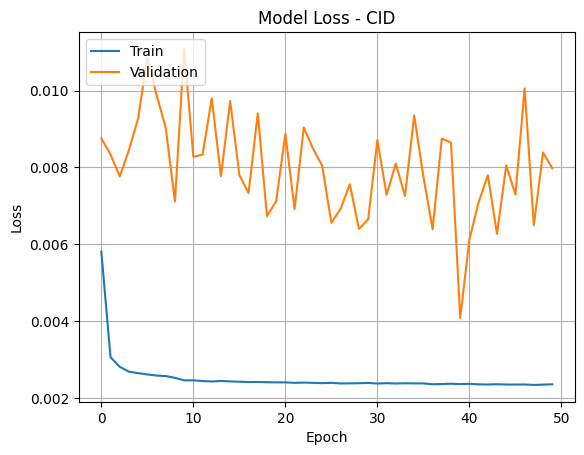

16120/16120 ━━━━━━━━━━━━━━━━━━━━ 7s 446us/step


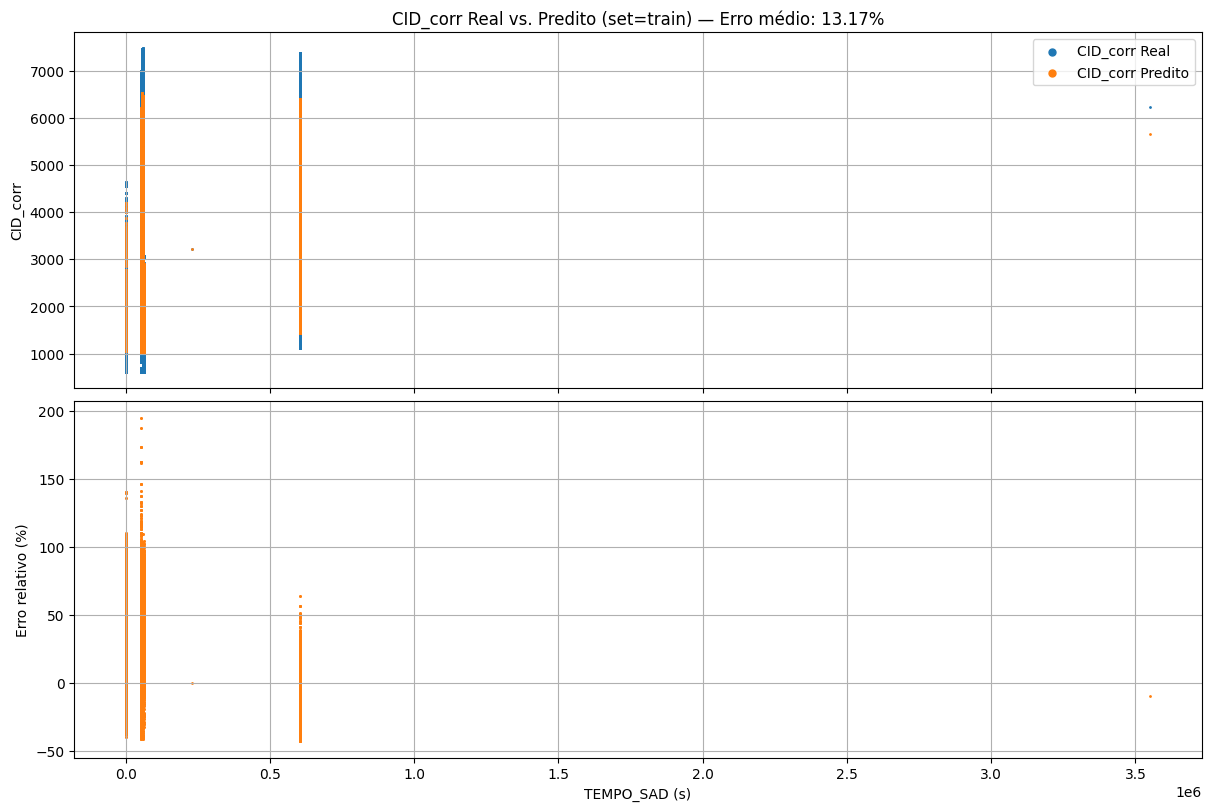

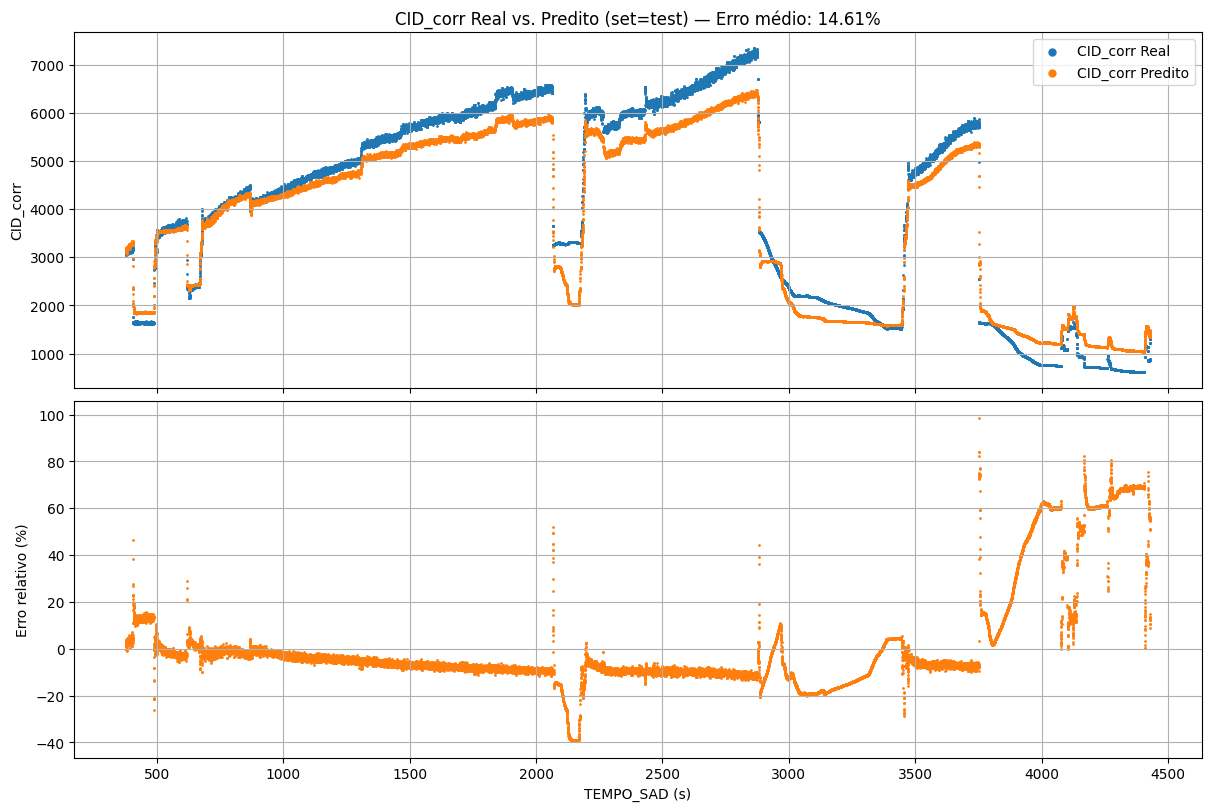

In [46]:
architecture_cid = {
    'neurons': 32,
    'camadas_ocultas': 3,
    'activation': 'relu',
    'dropout': 0.2
}
hyperparameters_cid = {
    'optimizer': 'adam',
    'learning_rate': 0.001,
    'epochs': 150,
    'batch_size': 64,
    'patience': 10
}
df, scaler_x_cid, scaler_y_cid, model_cid, training_history_cid = pipeline_cid(
    df, features_cid, target_cid, architecture_cid, hyperparameters_cid
)
plotgraphs(training_history_cid, df)

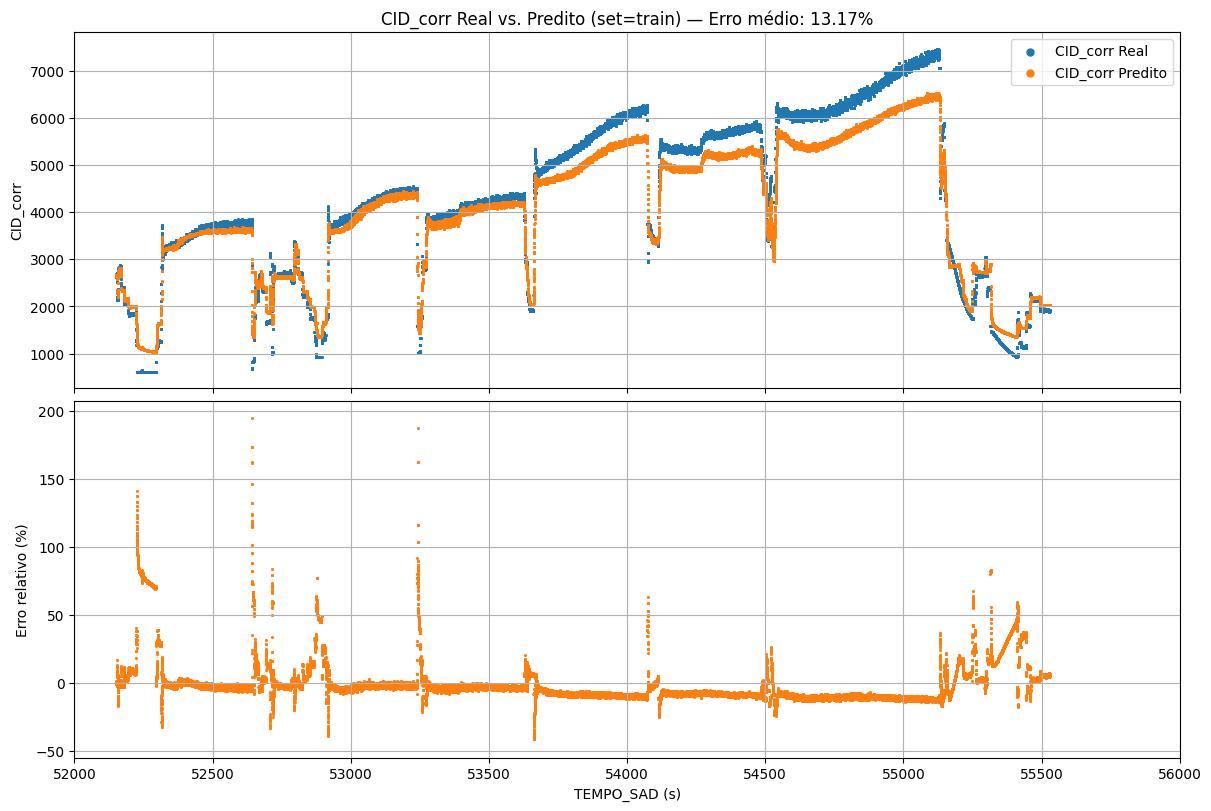

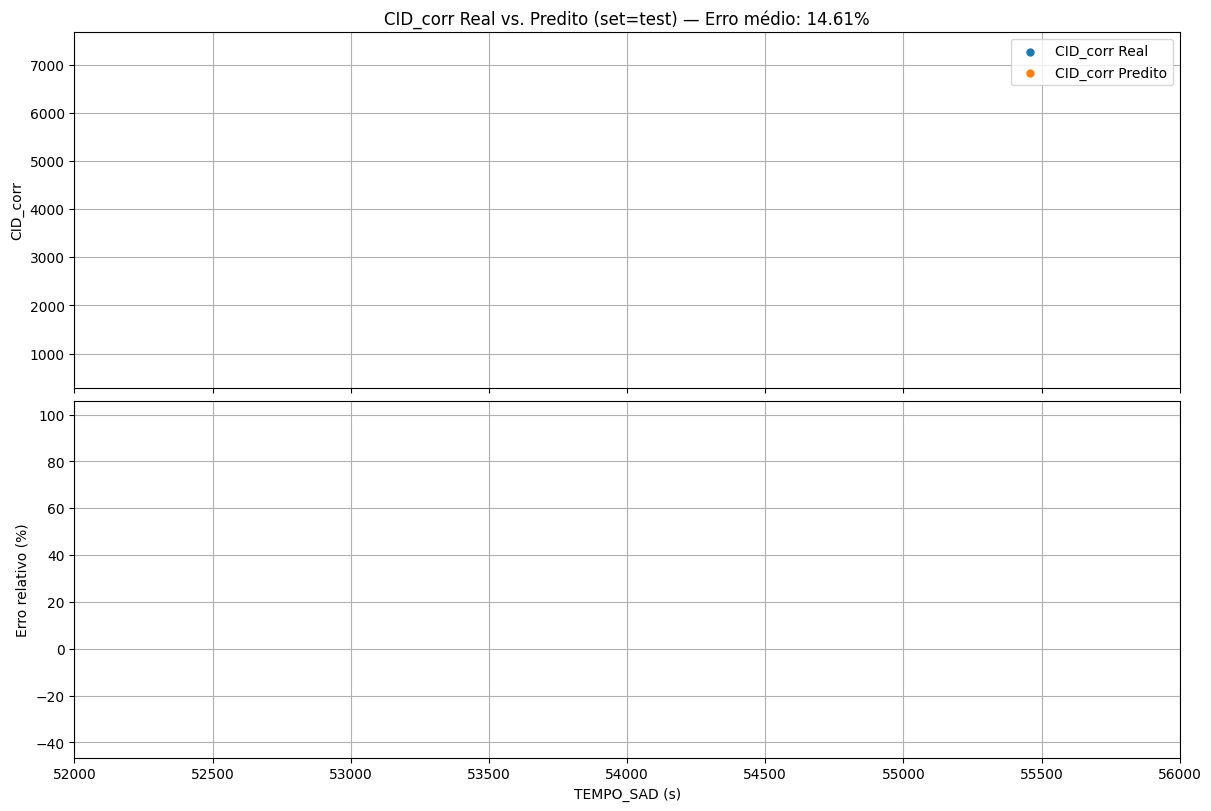

In [47]:
# plt.plot(training_history_cid.history['loss'])
# plt.plot(training_history_cid.history['val_loss'])
# plt.title('Model Loss - CID')
# plt.ylabel('Loss')
# plt.xlabel('Epoch')
# plt.legend(['Train', 'Validation'], loc='upper left')
# plt.grid()
# plt.show()

# # =========================================================
# # Comparação CID_corr: Real vs. Predito
# # =========================================================

# features_cid_scaled = [f + '_scaled' for f in features_cid]
# X_cid_all = np.array(df[features_cid_scaled]).astype(np.float32)

# pred_scaled_cid = model_cid.predict(X_cid_all)
# df['CID_corr_pred'] = scaler_y_cid.inverse_transform(pred_scaled_cid).flatten()

# plt.show()
for evaluated_set in ['train', 'test']:
    subset = df[df['type'] == evaluated_set]

    erro_relativo_cid = (subset['CID_corr_pred'] - subset['CID_corr']) / subset['CID_corr'].abs() * 100
    erro_medio_cid = np.nanmean(np.abs(erro_relativo_cid))

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)

    axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr'], s=1, label='CID_corr Real')
    axes[0].scatter(subset['TEMPO_SAD'], subset['CID_corr_pred'], s=1, label='CID_corr Predito')
    axes[0].set_ylabel('CID_corr')
    axes[0].set_title(f'CID_corr Real vs. Predito (set={evaluated_set}) — Erro médio: {erro_medio_cid:.2f}%')
    axes[0].legend(markerscale=5)
    axes[0].grid()

    axes[1].scatter(subset['TEMPO_SAD'], erro_relativo_cid, s=1, color='tab:orange')
    axes[1].set_ylabel('Erro relativo (%)')
    axes[1].set_xlabel('TEMPO_SAD (s)')
    axes[1].grid()

    axes[1].set_xlim(52000, 56000)  # Ajuste conforme necessário

    plt.show()

# Grid Search:

In [52]:
def model_constructor_grid_search(features1, features2, targets, neurons, optimizer, learning_rate, batch_size, epochs, activation):
    return build_model(
        features1=features1,
        features2=features2,
        targets=targets,
        architecture={
            'neurons': neurons,
            'camadas_ocultas': 2,
            'activation': activation,
            'dropout': 0.5
        },
        hyperparameters={
            'optimizer': optimizer,
            'learning_rate': learning_rate,
            'epochs': epochs,
            'batch_size': batch_size,
            'patience': 3
        }
    )

In [ ]:
features1_scaled = [f + '_scaled' for f in ['Mach', 'N1_over_sqrt_theta', 'W', 'Va']]
features2_scaled = [f + '_scaled' for f in ['Mach', 'CL', 'W', 'Va']]
targets_scaled   = ['Hdot_scaled']

split_idx = len(features1_scaled)  # índice de corte no array concatenado

def model_constructor_grid_search(neurons, optimizer, learning_rate,
                                   batch_size, epochs, activation):
    """
    KerasRegressor passa X como array único — separamos X1 e X2
    pelo split_idx definido no escopo externo.
    A separação real acontece dentro do Keras via Lambda.
    """

    n1 = len(features1_scaled)
    n2 = len(features2_scaled)

    # Entrada única concatenada (o que o GridSearchCV enxerga)
    input_combined = layers.Input(shape=(n1 + n2,), name='Entrada_combinada')

    # Separação interna
    input_x1 = layers.Lambda(lambda x: x[:, :n1],    name='Split_X1')(input_combined)
    input_x2 = layers.Lambda(lambda x: x[:, n1:],    name='Split_X2')(input_combined)

    def subnetwork(tensor, prefix, camadas_ocultas=2):
        x = tensor
        for i in range(camadas_ocultas):
            x = layers.Dense(neurons, activation=activation,
                             name=f'{prefix}_hidden_{i+1}')(x)
            x = layers.Dropout(0.5, name=f'{prefix}_dropout_{i+1}')(x)
        return layers.Dense(1, name=f'{prefix}_output')(x)

    z1 = subnetwork(input_x1, 'NN1')
    z2 = subnetwork(input_x2, 'NN2')

    output = layers.Subtract(name='Saida_Y')([z1, z2])
    model  = Model(inputs=input_combined, outputs=output)

    opt = keras.optimizers.get({
        'class_name': optimizer,
        'config': {'learning_rate': learning_rate}
    })
    model.compile(optimizer=opt, loss='mse')
    return model


model_wrapper = KerasRegressor(
    model=model_constructor_grid_search,
    verbose=1
)

param_grid = {
    'model__neurons':        [60, 80, 100, 120, 150],
    'model__optimizer':      ['adam'],
    'model__activation':     ['relu', 'tanh', 'sigmoid'],  # corrigido
    'model__learning_rate':  [0.001, 0.0001, 0.00001],
    'model__batch_size':     [32, 64, 128, 256],
    'model__epochs':         [80, 100, 120, 140],
}

X1_train_s = np.array(df.loc[df['type'] == 'train', features1_scaled]).astype(np.float32)
X2_train_s = np.array(df.loc[df['type'] == 'train', features2_scaled]).astype(np.float32)
Y_train_s  = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32)

# Concatena X1 e X2 — GridSearchCV aceita array único
X_train_s = np.hstack([X1_train_s, X2_train_s])

grid = GridSearchCV(
    model_wrapper,
    param_grid=param_grid,
    scoring='neg_mean_absolute_error',
    cv=3,
    n_jobs=-1
)

grid_result = grid.fit(X_train_s, Y_train_s)

# grid_result.append(...) não existe — para salvar os resultados:
import pandas as pd
results_df = pd.DataFrame(grid_result.cv_results_)
print("Melhores parâmetros:", grid_result.best_params_)
print("Melhor MAE:         ", -grid_result.best_score_)

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Melhores parâmetros: {'model__activation': 'tanh', 'model__batch_size': 256, 'model__epochs': 140, 'model__learning_rate': 0.001, 'model__neurons': 150, 'model__optimizer': 'adam'}
Melhor MAE:          0.10863187288244565


23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


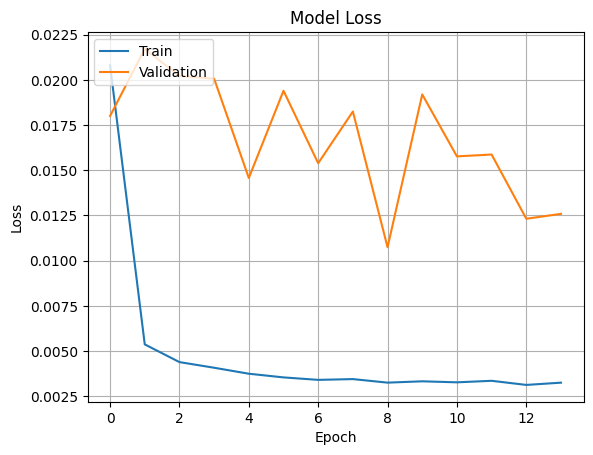

C:\Users\ymarc\AppData\Local\Temp\ipykernel_7756\242009600.py:64: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


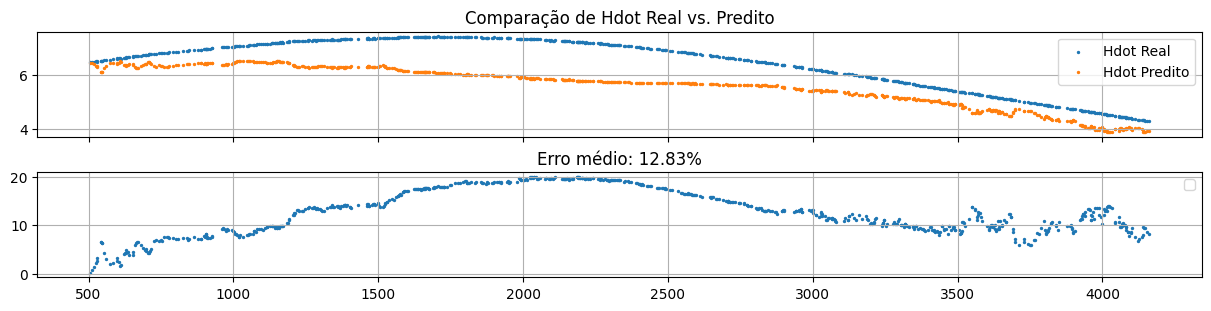

Erro máximo: 19.969042


In [199]:
df, scaler_x1, scaler_x2, scaler_y, model, training_history, results = analyze(
    tipo_dados='aceleracao_nivelada',
    features1=['T', 'W', 'Vcorr'],
    features2=['CD', 'W', 'CL', 'Vcorr'],
    targets=['Hdot'],
    architecture={
        'neurons': 50,
        'camadas_ocultas': 1,
        'activation': 'relu',
        'dropout': 0.5
    },
    hyperparameters={
        'optimizer': 'adam',
        'learning_rate': 0.001,
        'epochs': 50,
        'batch_size': 32,
        'patience': 5
    }
)
print("Erro máximo:", np.nanmax(results["rel_error"]))